In [ ]:

# Install required libraries

!pip install -q librosa nltk scikit-learn seaborn


In [ ]:

import os
import random
import subprocess
import tarfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import librosa
import nltk

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
print("Librosa version:", librosa.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


All libraries imported successfully!
TensorFlow version: 2.21.0
Librosa version: 0.11.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seeds configured successfully!")
print("Seed:", SEED)


Random seeds configured successfully!
Seed: 42


In [ ]:

DATASET_URL = "https://huggingface.co/datasets/declare-lab/MELD/resolve/main/MELD.Raw.tar.gz"

DATASET_ARCHIVE = "/content/MELD.Raw.tar.gz"

if not os.path.exists(DATASET_ARCHIVE):
    !wget -q "{DATASET_URL}" -O "{DATASET_ARCHIVE}"

if os.path.exists(DATASET_ARCHIVE):
    print("MELD dataset downloaded successfully!")
    print("File size:", round(os.path.getsize(DATASET_ARCHIVE) / (1024 * 1024), 2), "MB")
else:
    print("Dataset download failed!")


MELD dataset downloaded successfully!
File size: 10374.21 MB


In [ ]:

BASE_DIR = Path("/content/MELD/MELD.Raw")

BASE_DIR.mkdir(parents=True, exist_ok=True)

with tarfile.open(DATASET_ARCHIVE, "r:gz") as tar:
    tar.extractall(
        path="/content/MELD",
        filter="data"
    )

print("MELD dataset extracted successfully!")
print("Dataset directory:", BASE_DIR)
print("Directory exists:", BASE_DIR.exists())


MELD dataset extracted successfully!
Dataset directory: /content/MELD/MELD.Raw
Directory exists: True


In [ ]:

print("MELD dataset contents:\n")

for item in sorted(BASE_DIR.iterdir()):
    if item.is_dir():
        print("[FOLDER]", item.name)
    else:
        print("[FILE]", item.name)

print("\nDataset directory verified:", BASE_DIR.exists())


MELD dataset contents:

[FILE] ._train_splits
[FILE] README.txt
[FILE] dev.tar.gz
[FILE] dev_sent_emo.csv
[FILE] test.tar.gz
[FILE] test_sent_emo.csv
[FILE] train.tar.gz

Dataset directory verified: True


In [ ]:

TRAIN_CSV = BASE_DIR / "train_sent_emo.csv"

if not TRAIN_CSV.exists():
    train_csv_url = (
        "https://raw.githubusercontent.com/declare-lab/MELD/"
        "master/data/MELD/train_sent_emo.csv"
    )

    response = requests.get(train_csv_url)
    response.raise_for_status()

    with open(TRAIN_CSV, "wb") as file:
        file.write(response.content)

print("Training CSV available:", TRAIN_CSV.exists())
print("Training CSV size:", TRAIN_CSV.stat().st_size, "bytes")


Training CSV available: True
Training CSV size: 1119290 bytes


In [ ]:
import requests

In [ ]:

TRAIN_CSV = BASE_DIR / "train_sent_emo.csv"
VAL_CSV = BASE_DIR / "dev_sent_emo.csv"
TEST_CSV = BASE_DIR / "test_sent_emo.csv"

# Verify files
for path in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    assert path.exists(), f"Missing file: {path}"

# Load datasets
train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)
test_df = pd.read_csv(TEST_CSV)

print("All datasets loaded successfully!\n")

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nFirst five training records:")
display(train_df.head())


All datasets loaded successfully!

Training shape: (9989, 11)
Validation shape: (1109, 11)
Testing shape: (2610, 11)

Training columns:
['Sr No.', 'Utterance', 'Speaker', 'Emotion', 'Sentiment', 'Dialogue_ID', 'Utterance_ID', 'Season', 'Episode', 'StartTime', 'EndTime']

First five training records:


,Sr No.,Utterance,Speaker,Emotion,Sentiment,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime
0,1,also I was the point person on my company’s tr...,Chandler,neutral,neutral,0,0,8,21,"00:16:16,059","00:16:21,731"
1,2,You must’ve had your hands full.,The Interviewer,neutral,neutral,0,1,8,21,"00:16:21,940","00:16:23,442"
2,3,That I did. That I did.,Chandler,neutral,neutral,0,2,8,21,"00:16:23,442","00:16:26,389"
3,4,So let’s talk a little bit about your duties.,The Interviewer,neutral,neutral,0,3,8,21,"00:16:26,820","00:16:29,572"
4,5,My duties? All right.,Chandler,surprise,positive,0,4,8,21,"00:16:34,452","00:16:40,917"


In [ ]:

def clean_dataset(df):
    df = df.copy()

    # Remove unnecessary column
    df = df.drop(columns=["Sr No."], errors="ignore")

    # Clean text and labels
    df["Utterance"] = df["Utterance"].fillna("").astype(str).str.strip()
    df["Emotion"] = df["Emotion"].astype(str).str.strip().str.lower()
    df["Sentiment"] = df["Sentiment"].astype(str).str.strip().str.lower()

    # Remove missing or empty utterances and emotion labels
    df = df[
        (df["Utterance"] != "") &
        (df["Emotion"] != "") &
        (df["Emotion"] != "nan")
    ]

    return df.reset_index(drop=True)


train_df = clean_dataset(train_df)
val_df = clean_dataset(val_df)
test_df = clean_dataset(test_df)

print("Dataset cleaning completed!")

print("\nTraining:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nEmotion classes:")
print(sorted(train_df["Emotion"].unique()))

print("\nTraining emotion distribution:")
print(train_df["Emotion"].value_counts())


Dataset cleaning completed!

Training: (9989, 10)
Validation: (1109, 10)
Testing: (2610, 10)

Emotion classes:
['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']

Training emotion distribution:
Emotion
neutral     4710
joy         1743
surprise    1205
anger       1109
sadness      683
disgust      271
fear         268
Name: count, dtype: int64


In [ ]:

EMOTIONS = [
    "anger",
    "disgust",
    "fear",
    "joy",
    "neutral",
    "sadness",
    "surprise"
]

emotion_to_id = {
    emotion: index
    for index, emotion in enumerate(EMOTIONS)
}

id_to_emotion = {
    index: emotion
    for emotion, index in emotion_to_id.items()
}

# Convert emotion names into numerical labels
train_df["label"] = train_df["Emotion"].map(emotion_to_id)
val_df["label"] = val_df["Emotion"].map(emotion_to_id)
test_df["label"] = test_df["Emotion"].map(emotion_to_id)

print("Emotion encoding completed!\n")

print("Emotion mapping:")
print(emotion_to_id)

print("\nFirst 10 training labels:")
print(train_df[["Emotion", "label"]].head(10))

print("\nNumber of classes:", len(EMOTIONS))


Emotion encoding completed!

Emotion mapping:
{'anger': 0, 'disgust': 1, 'fear': 2, 'joy': 3, 'neutral': 4, 'sadness': 5, 'surprise': 6}

First 10 training labels:
    Emotion  label
0   neutral      4
1   neutral      4
2   neutral      4
3   neutral      4
4  surprise      6
5   neutral      4
6   neutral      4
7   neutral      4
8   neutral      4
9   neutral      4

Number of classes: 7


In [ ]:

audio_archives = {
    "train.tar.gz": "train_splits",
    "dev.tar.gz": "dev_splits_complete",
    "test.tar.gz": "output_repeated_splits_test"
}

for archive_name, folder_name in audio_archives.items():

    archive_path = BASE_DIR / archive_name
    folder_path = BASE_DIR / folder_name

    if not archive_path.exists():
        raise FileNotFoundError(f"Archive missing: {archive_path}")

    existing_files = list(folder_path.rglob("*.mp4")) if folder_path.exists() else []

    if existing_files:
        print(f"{folder_name} already extracted. Skipping.")
        continue

    print(f"\nExtracting {archive_name}...")

    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(path=BASE_DIR, filter="data")

    print(f"{folder_name} extraction completed!")

print("\nAll audio archives processed!")



Extracting train.tar.gz...
train_splits extraction completed!

Extracting dev.tar.gz...
dev_splits_complete extraction completed!

Extracting test.tar.gz...
output_repeated_splits_test extraction completed!

All audio archives processed!


In [ ]:

audio_folders = {
    "Training": BASE_DIR / "train_splits",
    "Validation": BASE_DIR / "dev_splits_complete",
    "Testing": BASE_DIR / "output_repeated_splits_test"
}

for split_name, folder_path in audio_folders.items():

    mp4_files = list(folder_path.rglob("*.mp4"))

    print(f"{split_name}: {len(mp4_files)} MP4 files")

print("\nAudio extraction verification completed!")


Training: 9989 MP4 files
Validation: 1112 MP4 files
Testing: 4807 MP4 files

Audio extraction verification completed!


In [ ]:

def create_audio_map(folder_path):
    audio_map = {}

    for file_path in folder_path.rglob("*.mp4"):

        filename = file_path.stem.lower()

        # Ignore hidden Apple metadata files
        if filename.startswith("._"):
            continue

        audio_map[filename] = str(file_path)

    return audio_map


train_audio_map = create_audio_map(BASE_DIR / "train_splits")

val_audio_map = create_audio_map(BASE_DIR / "dev_splits_complete")

test_audio_map = create_audio_map(BASE_DIR / "output_repeated_splits_test")


print("Audio mappings created!\n")

print("Training audio mappings:", len(train_audio_map))
print("Validation audio mappings:", len(val_audio_map))
print("Testing audio mappings:", len(test_audio_map))

print("\nSample training audio mappings:")

for key, value in list(train_audio_map.items())[:5]:
    print(key, ":", value)


Audio mappings created!

Training audio mappings: 9989
Validation audio mappings: 1112
Testing audio mappings: 2747

Sample training audio mappings:
dia311_utt6 : /content/MELD/MELD.Raw/train_splits/dia311_utt6.mp4
dia529_utt7 : /content/MELD/MELD.Raw/train_splits/dia529_utt7.mp4
dia288_utt17 : /content/MELD/MELD.Raw/train_splits/dia288_utt17.mp4
dia939_utt2 : /content/MELD/MELD.Raw/train_splits/dia939_utt2.mp4
dia384_utt1 : /content/MELD/MELD.Raw/train_splits/dia384_utt1.mp4


In [ ]:
def attach_audio_paths(df, audio_map):
    df = df.copy()

    df["audio_key"] = df.apply(
        lambda row: f"dia{int(row['Dialogue_ID'])}_utt{int(row['Utterance_ID'])}",
        axis=1
    )

    df["audio_path"] = df["audio_key"].map(audio_map)

    return df


train_df = attach_audio_paths(train_df, train_audio_map)
val_df = attach_audio_paths(val_df, val_audio_map)
test_df = attach_audio_paths(test_df, test_audio_map)


for split_name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    matched = df["audio_path"].notna().sum()
    missing = df["audio_path"].isna().sum()

    print(f"\n{split_name} dataset:")
    print("Total records:", len(df))
    print("Matched audio files:", matched)
    print("Missing audio files:", missing)


print("\nSample matched records:")
display(train_df[["Utterance", "Emotion", "audio_key", "audio_path"]].head())


Training dataset:
Total records: 9989
Matched audio files: 9989
Missing audio files: 0

Validation dataset:
Total records: 1109
Matched audio files: 1108
Missing audio files: 1

Testing dataset:
Total records: 2610
Matched audio files: 2610
Missing audio files: 0

Sample matched records:


,Utterance,Emotion,audio_key,audio_path
0,also I was the point person on my company’s tr...,neutral,dia0_utt0,/content/MELD/MELD.Raw/train_splits/dia0_utt0.mp4
1,You must’ve had your hands full.,neutral,dia0_utt1,/content/MELD/MELD.Raw/train_splits/dia0_utt1.mp4
2,That I did. That I did.,neutral,dia0_utt2,/content/MELD/MELD.Raw/train_splits/dia0_utt2.mp4
3,So let’s talk a little bit about your duties.,neutral,dia0_utt3,/content/MELD/MELD.Raw/train_splits/dia0_utt3.mp4
4,My duties? All right.,surprise,dia0_utt4,/content/MELD/MELD.Raw/train_splits/dia0_utt4.mp4


In [ ]:
missing_val = val_df[val_df["audio_path"].isna()]

print("Missing validation records:")
display(
    missing_val[
        ["Dialogue_ID", "Utterance_ID", "Utterance", "Emotion", "audio_key"]
    ]
)

Missing validation records:


,Dialogue_ID,Utterance_ID,Utterance,Emotion,audio_key
1084,110,7,Did they tell you anything?,neutral,dia110_utt7


In [ ]:
# Keep only records that have a valid audio path
train_audio_df = train_df[train_df["audio_path"].notna()].copy()
val_audio_df = val_df[val_df["audio_path"].notna()].copy()
test_audio_df = test_df[test_df["audio_path"].notna()].copy()

# Reset row indexes
train_audio_df = train_audio_df.reset_index(drop=True)
val_audio_df = val_audio_df.reset_index(drop=True)
test_audio_df = test_audio_df.reset_index(drop=True)

print("Audio datasets prepared successfully!\n")

print("Training records:", len(train_audio_df))
print("Validation records:", len(val_audio_df))
print("Testing records:", len(test_audio_df))

print("\nMissing audio records after preparation:")
print("Training:", train_audio_df["audio_path"].isna().sum())
print("Validation:", val_audio_df["audio_path"].isna().sum())
print("Testing:", test_audio_df["audio_path"].isna().sum())

Audio datasets prepared successfully!

Training records: 9989
Validation records: 1108
Testing records: 2610

Missing audio records after preparation:
Training: 0
Validation: 0
Testing: 0


In [ ]:
SAMPLE_RATE = 22050
N_MFCC = 40
MAX_AUDIO_LENGTH = 200

print("Audio feature extraction settings:\n")
print("Sample rate:", SAMPLE_RATE)
print("MFCC coefficients:", N_MFCC)
print("Maximum audio frames:", MAX_AUDIO_LENGTH)

Audio feature extraction settings:

Sample rate: 22050
MFCC coefficients: 40
Maximum audio frames: 200


In [ ]:
import io

def extract_mfcc(audio_path):
    try:
        # Convert MP4 audio into WAV data using FFmpeg
        result = subprocess.run(
            [
                "ffmpeg",
                "-v", "error",
                "-i", audio_path,
                "-vn",
                "-ac", "1",
                "-ar", str(SAMPLE_RATE),
                "-f", "wav",
                "pipe:1"
            ],
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE,
            check=True,
            timeout=30
        )

        # Load audio data
        audio, sr = librosa.load(
            io.BytesIO(result.stdout),
            sr=SAMPLE_RATE,
            mono=True
        )

        # Extract MFCC features
        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=sr,
            n_mfcc=N_MFCC
        )

        return mfcc.T.astype(np.float32)

    except Exception as e:
        print("Audio processing failed:", audio_path)
        print("Error:", str(e))
        return None


# Test using the first training audio file
sample_audio_path = train_audio_df.loc[0, "audio_path"]

sample_mfcc = extract_mfcc(sample_audio_path)

if sample_mfcc is not None:
    print("Audio feature extraction successful!")
    print("Audio file:", sample_audio_path)
    print("MFCC shape:", sample_mfcc.shape)
    print("Data type:", sample_mfcc.dtype)
else:
    print("Sample audio extraction failed!")

Audio feature extraction successful!
Audio file: /content/MELD/MELD.Raw/train_splits/dia0_utt0.mp4
MFCC shape: (245, 40)
Data type: float32


In [ ]:
def fix_audio_length(mfcc, max_length=MAX_AUDIO_LENGTH):
    if mfcc.shape[0] > max_length:
        mfcc = mfcc[:max_length]

    elif mfcc.shape[0] < max_length:
        padding = np.zeros(
            (max_length - mfcc.shape[0], N_MFCC),
            dtype=np.float32
        )

        mfcc = np.vstack((mfcc, padding))

    return mfcc.astype(np.float32)


# Apply fixed-length preparation to our sample
sample_fixed_mfcc = fix_audio_length(sample_mfcc)

print("Original MFCC shape:", sample_mfcc.shape)
print("Fixed MFCC shape:", sample_fixed_mfcc.shape)
print("Data type:", sample_fixed_mfcc.dtype)

Original MFCC shape: (245, 40)
Fixed MFCC shape: (200, 40)
Data type: float32


In [ ]:
sample_features = []
failed_files = []

for index in range(10):
    audio_path = train_audio_df.loc[index, "audio_path"]

    mfcc = extract_mfcc(audio_path)

    if mfcc is not None:
        fixed_mfcc = fix_audio_length(mfcc)
        sample_features.append(fixed_mfcc)
    else:
        failed_files.append(audio_path)

sample_features = np.array(sample_features, dtype=np.float32)

print("Batch audio processing completed!\n")
print("Successfully processed:", len(sample_features))
print("Failed files:", len(failed_files))
print("Feature array shape:", sample_features.shape)
print("Data type:", sample_features.dtype)

Batch audio processing completed!

Successfully processed: 10
Failed files: 0
Feature array shape: (10, 200, 40)
Data type: float32


In [ ]:
def process_audio_dataset(df, split_name):
    features = []
    labels = []
    failed_files = []

    checkpoint_dir = Path("/content/MELD/checkpoints")
    checkpoint_dir.mkdir(parents=True, exist_ok=True)

    for index, row in df.iterrows():

        audio_path = row["audio_path"]

        mfcc = extract_mfcc(audio_path)

        if mfcc is not None:
            fixed_mfcc = fix_audio_length(mfcc)
            features.append(fixed_mfcc)
            labels.append(row["label"])
        else:
            failed_files.append(audio_path)

        if (index + 1) % 250 == 0:
            print(
                f"{split_name}: Processed {index + 1}/{len(df)}"
            )

            np.save(
                checkpoint_dir / f"{split_name}_features_checkpoint.npy",
                np.array(features, dtype=np.float32)
            )

    features = np.array(features, dtype=np.float32)
    labels = np.array(labels, dtype=np.int32)

    np.save(checkpoint_dir / f"{split_name}_features.npy", features)
    np.save(checkpoint_dir / f"{split_name}_labels.npy", labels)

    print(f"\n{split_name} processing completed!")
    print("Successful:", len(features))
    print("Failed:", len(failed_files))
    print("Feature shape:", features.shape)
    print("Label shape:", labels.shape)

    return features, labels, failed_files


# Process training audio
X_audio_train, y_audio_train, failed_train = process_audio_dataset(
    train_audio_df, "train"
)

train: Processed 250/9989
train: Processed 500/9989
train: Processed 750/9989
train: Processed 1000/9989
Audio processing failed: /content/MELD/MELD.Raw/train_splits/dia125_utt3.mp4
Error: Command '['ffmpeg', '-v', 'error', '-i', '/content/MELD/MELD.Raw/train_splits/dia125_utt3.mp4', '-vn', '-ac', '1', '-ar', '22050', '-f', 'wav', 'pipe:1']' returned non-zero exit status 183.
train: Processed 1250/9989
train: Processed 1500/9989
train: Processed 1750/9989
train: Processed 2000/9989
train: Processed 2250/9989
train: Processed 2500/9989
train: Processed 2750/9989
train: Processed 3000/9989
train: Processed 3250/9989
train: Processed 3500/9989
train: Processed 3750/9989
train: Processed 4000/9989
train: Processed 4250/9989
train: Processed 4500/9989
train: Processed 4750/9989
train: Processed 5000/9989
train: Processed 5250/9989
train: Processed 5500/9989
train: Processed 5750/9989
train: Processed 6000/9989
train: Processed 6250/9989
train: Processed 6500/9989
train: Processed 6750/9989


In [ ]:
# Check training audio features

print("Training audio feature verification\n")

print("Features shape:", X_audio_train.shape)
print("Labels shape:", y_audio_train.shape)

print("\nFeature data type:", X_audio_train.dtype)
print("Label data type:", y_audio_train.dtype)

print("\nMissing values in features:", np.isnan(X_audio_train).sum())
print("Infinite values in features:", np.isinf(X_audio_train).sum())

print("\nEmotion distribution in audio training data:")

unique_labels, counts = np.unique(y_audio_train, return_counts=True)

for label, count in zip(unique_labels, counts):
    print(id_to_emotion[label], ":", count)

Training audio feature verification

Features shape: (9988, 200, 40)
Labels shape: (9988,)

Feature data type: float32
Label data type: int32

Missing values in features: 0
Infinite values in features: 0

Emotion distribution in audio training data:
anger : 1109
disgust : 271
fear : 268
joy : 1743
neutral : 4709
sadness : 683
surprise : 1205


In [ ]:
# Process validation audio

X_audio_val, y_audio_val, failed_val = process_audio_dataset(
    val_audio_df, "validation"
)

validation: Processed 250/1108
validation: Processed 500/1108
validation: Processed 750/1108
validation: Processed 1000/1108

validation processing completed!
Successful: 1108
Failed: 0
Feature shape: (1108, 200, 40)
Label shape: (1108,)


In [ ]:
# Process testing audio

X_audio_test, y_audio_test, failed_test = process_audio_dataset(
    test_audio_df, "test"
)

test: Processed 250/2610
test: Processed 500/2610
test: Processed 750/2610
test: Processed 1000/2610
test: Processed 1250/2610
test: Processed 1500/2610
test: Processed 1750/2610
test: Processed 2000/2610
test: Processed 2250/2610
test: Processed 2500/2610

test processing completed!
Successful: 2610
Failed: 0
Feature shape: (2610, 200, 40)
Label shape: (2610,)


In [ ]:
# Verify all audio datasets

audio_datasets = {
    "Training": (X_audio_train, y_audio_train),
    "Validation": (X_audio_val, y_audio_val),
    "Testing": (X_audio_test, y_audio_test)
}

for split_name, (features, labels) in audio_datasets.items():

    print(f"\n{split_name} dataset:")
    print("Features shape:", features.shape)
    print("Labels shape:", labels.shape)
    print("Missing values:", np.isnan(features).sum())
    print("Infinite values:", np.isinf(features).sum())
    print("Matching feature-label count:", len(features) == len(labels))

print("\nAll audio dataset verification completed!")


Training dataset:
Features shape: (9988, 200, 40)
Labels shape: (9988,)
Missing values: 0
Infinite values: 0
Matching feature-label count: True

Validation dataset:
Features shape: (1108, 200, 40)
Labels shape: (1108,)
Missing values: 0
Infinite values: 0
Matching feature-label count: True

Testing dataset:
Features shape: (2610, 200, 40)
Labels shape: (2610,)
Missing values: 0
Infinite values: 0
Matching feature-label count: True

All audio dataset verification completed!


In [ ]:
# Normalize MFCC features while preserving zero padding

def normalize_audio_features(features):

    normalized_features = np.zeros_like(features, dtype=np.float32)

    for i in range(len(features)):

        sample = features[i]

        # Identify frames that are not padding
        valid_frames = np.any(sample != 0, axis=1)

        # Normalize only actual audio frames
        valid_sample = sample[valid_frames]

        mean = np.mean(valid_sample, axis=0)
        std = np.std(valid_sample, axis=0)

        std[std == 0] = 1.0

        normalized_features[i, valid_frames] = (
            (valid_sample - mean) / std
        )

    return normalized_features


X_audio_train = normalize_audio_features(X_audio_train)
X_audio_val = normalize_audio_features(X_audio_val)
X_audio_test = normalize_audio_features(X_audio_test)

print("Audio normalization completed!")

print("\nTraining shape:", X_audio_train.shape)
print("Validation shape:", X_audio_val.shape)
print("Testing shape:", X_audio_test.shape)

print("\nTraining mean:", np.mean(X_audio_train))
print("Training standard deviation:", np.std(X_audio_train))

Audio normalization completed!

Training shape: (9988, 200, 40)
Validation shape: (1108, 200, 40)
Testing shape: (2610, 200, 40)

Training mean: 1.2311212e-10
Training standard deviation: 0.7590312


In [ ]:
# Verify zero-padding preservation

for split_name, features in [
    ("Training", X_audio_train),
    ("Validation", X_audio_val),
    ("Testing", X_audio_test)
]:
    zero_frames = np.all(features == 0, axis=2)

    print(f"\n{split_name}:")
    print("Number of padded frames:", zero_frames.sum())
    print("All values finite:", np.isfinite(features).all())

print("\nPadding verification completed!")


Training:
Number of padded frames: 846726
All values finite: True

Validation:
Number of padded frames: 93807
All values finite: True

Testing:
Number of padded frames: 212795
All values finite: True

Padding verification completed!


In [ ]:
BATCH_SIZE = 32

train_audio_dataset = tf.data.Dataset.from_tensor_slices(
    (X_audio_train, y_audio_train)
)

val_audio_dataset = tf.data.Dataset.from_tensor_slices(
    (X_audio_val, y_audio_val)
)

test_audio_dataset = tf.data.Dataset.from_tensor_slices(
    (X_audio_test, y_audio_test)
)

train_audio_dataset = (
    train_audio_dataset
    .shuffle(2000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_audio_dataset = (
    val_audio_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_audio_dataset = (
    test_audio_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("TensorFlow audio datasets created successfully!")
print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_audio_dataset))
print("Validation batches:", len(val_audio_dataset))
print("Testing batches:", len(test_audio_dataset))

TensorFlow audio datasets created successfully!
Batch size: 32
Training batches: 313
Validation batches: 35
Testing batches: 82


In [ ]:
# Build Audio-BiGRU model

audio_input = tf.keras.layers.Input(
    shape=(MAX_AUDIO_LENGTH, N_MFCC),
    name="audio_input"
)

x = tf.keras.layers.Masking(
    mask_value=0.0
)(audio_input)

x = tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(64)
)(x)

x = tf.keras.layers.Dropout(0.3)(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu"
)(x)

audio_output = tf.keras.layers.Dense(
    len(EMOTIONS),
    activation="softmax"
)(x)

audio_model = tf.keras.Model(
    inputs=audio_input,
    outputs=audio_output,
    name="Audio_BiGRU"
)

audio_model.summary()

Model: "Audio_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio_input         │ (None, 200, 40)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 200, 40)   │          0 │ audio_input[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking (Masking)   │ (None, 200, 40)   │          0 │ audio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 200)       │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     40,704 │ masking[0][0],    │
│ (Bidirectional)     │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 7)         │        455 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 49,415 (193.03 KB)

 Trainable params: 49,415 (193.03 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile Audio-BiGRU model

audio_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Audio-BiGRU model compiled successfully!")
print("Optimizer: Adam")
print("Loss: Sparse Categorical Crossentropy")
print("Metric: Accuracy")

Audio-BiGRU model compiled successfully!
Optimizer: Adam
Loss: Sparse Categorical Crossentropy
Metric: Accuracy


In [ ]:
# Calculate class weights for imbalanced emotions

from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_audio_train),
    y=y_audio_train
)

audio_class_weights = {
    index: weight
    for index, weight in enumerate(class_weights)
}

print("Audio class weights:\n")

for emotion_id, weight in audio_class_weights.items():
    print(id_to_emotion[emotion_id], ":", round(weight, 4))

Audio class weights:

anger : 1.2866
disgust : 5.2652
fear : 5.3241
joy : 0.8186
neutral : 0.303
sadness : 2.0891
surprise : 1.1841


In [ ]:
# Configure callbacks

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/MELD/best_audio_bigru.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

# Train Audio-BiGRU model

audio_history = audio_model.fit(
    train_audio_dataset,
    validation_data=val_audio_dataset,
    epochs=30,
    class_weight=audio_class_weights,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/30
311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1521 - loss: 1.9994
Epoch 1: val_loss improved from None to 1.96301, saving model to /content/MELD/best_audio_bigru.keras

Epoch 1: finished saving model to /content/MELD/best_audio_bigru.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 22ms/step - accuracy: 0.1476 - loss: 1.9833 - val_accuracy: 0.1300 - val_loss: 1.9630
Epoch 2/30
310/313 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1587 - loss: 1.9065
Epoch 2: val_loss did not improve from 1.96301
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.1617 - loss: 1.9110 - val_accuracy: 0.1408 - val_loss: 1.9655
Epoch 3/30
311/313 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.1758 - loss: 1.8690
Epoch 3: val_loss improved from 1.96301 to 1.95721, saving model to /content/MELD/best_audio_bigru.keras

Epoch 3: finished saving model to /content/MELD/best_audio_bigru.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.1751 - loss: 1.8680 - val_accuracy: 0.1498 - val

In [ ]:
# Evaluate the trained Audio-BiGRU model

test_loss, test_accuracy = audio_model.evaluate(
    test_audio_dataset,
    verbose=1
)

print("\nAudio-BiGRU Test Results")
print("------------------------")
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

# Generate predictions

y_audio_pred_prob = audio_model.predict(
    test_audio_dataset,
    verbose=1
)

y_audio_pred = np.argmax(y_audio_pred_prob, axis=1)

# Classification report

print("\nClassification Report:\n")

print(
    classification_report(
        y_audio_test,
        y_audio_pred,
        target_names=EMOTIONS,
        zero_division=0
    )
)

82/82 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.1521 - loss: 1.9099

Audio-BiGRU Test Results
------------------------
Test Loss: 1.9099
Test Accuracy: 15.21 %
82/82 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step

Classification Report:

              precision    recall  f1-score   support

       anger       0.20      0.19      0.20       345
     disgust       0.03      0.13      0.05        68
        fear       0.03      0.20      0.05        50
         joy       0.20      0.10      0.13       402
     neutral       0.50      0.13      0.20      1256
     sadness       0.10      0.43      0.16       208
    surprise       0.11      0.09      0.10       281

    accuracy                           0.15      2610
   macro avg       0.17      0.18      0.13      2610
weighted avg       0.32      0.15      0.17      2610



Predicted Emotion Distribution:

anger : 336
disgust : 311
fear : 348
joy : 197
neutral : 316
sadness : 881
surprise : 221


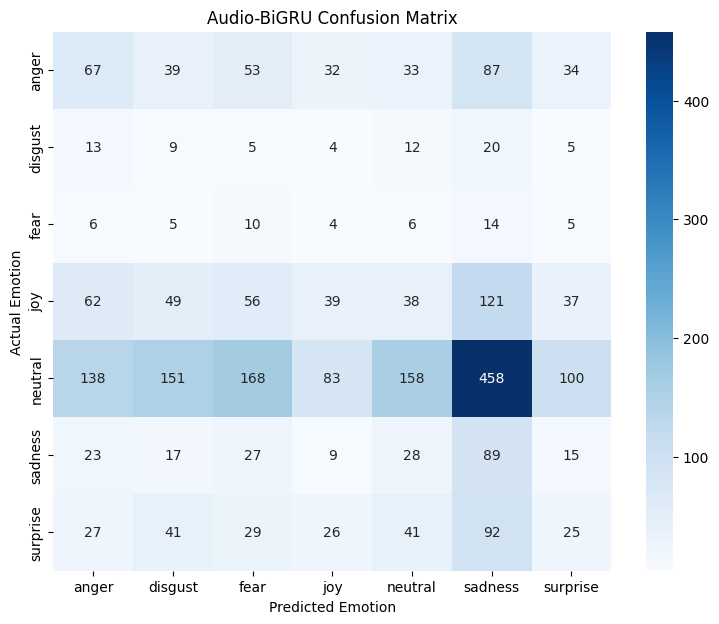

In [ ]:
# Check how often each emotion was predicted

print("Predicted Emotion Distribution:\n")

unique_predictions, prediction_counts = np.unique(
    y_audio_pred,
    return_counts=True
)

for emotion_id, count in zip(unique_predictions, prediction_counts):
    print(
        id_to_emotion[emotion_id],
        ":",
        count
    )

# Generate confusion matrix

cm = confusion_matrix(
    y_audio_test,
    y_audio_pred
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=EMOTIONS,
    yticklabels=EMOTIONS
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Audio-BiGRU Confusion Matrix")
plt.show()

In [ ]:
# Check actual emotion distribution in all audio splits

print("TRAINING LABEL DISTRIBUTION")
print("---------------------------")

for emotion_id, emotion in id_to_emotion.items():
    count = np.sum(y_audio_train == emotion_id)
    print(emotion, ":", count)

print("\nVALIDATION LABEL DISTRIBUTION")
print("-----------------------------")

for emotion_id, emotion in id_to_emotion.items():
    count = np.sum(y_audio_val == emotion_id)
    print(emotion, ":", count)

print("\nTEST LABEL DISTRIBUTION")
print("-----------------------")

for emotion_id, emotion in id_to_emotion.items():
    count = np.sum(y_audio_test == emotion_id)
    print(emotion, ":", count)

TRAINING LABEL DISTRIBUTION
---------------------------
anger : 1109
disgust : 271
fear : 268
joy : 1743
neutral : 4709
sadness : 683
surprise : 1205

VALIDATION LABEL DISTRIBUTION
-----------------------------
anger : 153
disgust : 22
fear : 40
joy : 163
neutral : 469
sadness : 111
surprise : 150

TEST LABEL DISTRIBUTION
-----------------------
anger : 345
disgust : 68
fear : 50
joy : 402
neutral : 1256
sadness : 208
surprise : 281


In [ ]:
# Inspect text dataset columns and sample records

print("Training columns:")
print(train_df.columns.tolist())

print("\nTraining sample:")
display(train_df.head(3))

print("\nValidation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Training columns:
['Utterance', 'Speaker', 'Emotion', 'Sentiment', 'Dialogue_ID', 'Utterance_ID', 'Season', 'Episode', 'StartTime', 'EndTime', 'label', 'audio_key', 'audio_path']

Training sample:


,Utterance,Speaker,Emotion,Sentiment,Dialogue_ID,Utterance_ID,Season,Episode,StartTime,EndTime,label,audio_key,audio_path
0,also I was the point person on my company’s tr...,Chandler,neutral,neutral,0,0,8,21,"00:16:16,059","00:16:21,731",4,dia0_utt0,/content/MELD/MELD.Raw/train_splits/dia0_utt0.mp4
1,You must’ve had your hands full.,The Interviewer,neutral,neutral,0,1,8,21,"00:16:21,940","00:16:23,442",4,dia0_utt1,/content/MELD/MELD.Raw/train_splits/dia0_utt1.mp4
2,That I did. That I did.,Chandler,neutral,neutral,0,2,8,21,"00:16:23,442","00:16:26,389",4,dia0_utt2,/content/MELD/MELD.Raw/train_splits/dia0_utt2.mp4



Validation shape: (1109, 13)
Test shape: (2610, 13)


In [ ]:
# Text preprocessing

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Set text preprocessing parameters

MAX_WORDS = 10000
MAX_TEXT_LENGTH = 50

# Create tokenizer

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Learn vocabulary only from training utterances

tokenizer.fit_on_texts(train_df["Utterance"])

# Convert text into sequences

train_sequences = tokenizer.texts_to_sequences(train_df["Utterance"])
val_sequences = tokenizer.texts_to_sequences(val_df["Utterance"])
test_sequences = tokenizer.texts_to_sequences(test_df["Utterance"])

# Pad sequences to equal length

X_text_train = pad_sequences(
    train_sequences,
    maxlen=MAX_TEXT_LENGTH,
    padding="post",
    truncating="post"
)

X_text_val = pad_sequences(
    val_sequences,
    maxlen=MAX_TEXT_LENGTH,
    padding="post",
    truncating="post"
)

X_text_test = pad_sequences(
    test_sequences,
    maxlen=MAX_TEXT_LENGTH,
    padding="post",
    truncating="post"
)

# Extract emotion labels

y_text_train = train_df["label"].values.astype(np.int32)
y_text_val = val_df["label"].values.astype(np.int32)
y_text_test = test_df["label"].values.astype(np.int32)

# Display results

print("Text preprocessing completed!")

print("\nTraining text shape:", X_text_train.shape)
print("Validation text shape:", X_text_val.shape)
print("Testing text shape:", X_text_test.shape)

print("\nTraining labels shape:", y_text_train.shape)
print("Validation labels shape:", y_text_val.shape)
print("Testing labels shape:", y_text_test.shape)

print("\nVocabulary size:", len(tokenizer.word_index))
print("\nSample padded sequence:")
print(X_text_train[0])

Text preprocessing completed!

Training text shape: (9989, 50)
Validation text shape: (1109, 50)
Testing text shape: (2610, 50)

Training labels shape: (9989,)
Validation labels shape: (1109,)
Testing labels shape: (2610,)

Vocabulary size: 5922

Sample padded sequence:
[ 429    2   35    4  754  430   29   20 2824 2825  128    4 2826 1135
    5 2827  884  885    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


In [ ]:
# Build Text-BiGRU model

text_input = tf.keras.layers.Input(
    shape=(MAX_TEXT_LENGTH,),
    name="text_input"
)

x = tf.keras.layers.Embedding(
    input_dim=MAX_WORDS,
    output_dim=128,
    mask_zero=True
)(text_input)

x = tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(64)
)(x)

x = tf.keras.layers.Dropout(0.3)(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu"
)(x)

text_output = tf.keras.layers.Dense(
    len(EMOTIONS),
    activation="softmax"
)(x)

text_model = tf.keras.Model(
    inputs=text_input,
    outputs=text_output,
    name="Text_BiGRU"
)

# Display model architecture

text_model.summary()

Model: "Text_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 50, 128)   │  1,280,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 50)        │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 128)       │     74,496 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 128)       │          0 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      8,256 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 7)         │        455 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,363,207 (5.20 MB)

 Trainable params: 1,363,207 (5.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile Text-BiGRU model

text_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Text-BiGRU model compiled successfully!")

Text-BiGRU model compiled successfully!


In [ ]:
# Calculate class weights for text data

from sklearn.utils.class_weight import compute_class_weight

text_class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_text_train),
    y=y_text_train
)

text_class_weights = {
    index: weight
    for index, weight in enumerate(text_class_weights)
}

print("Text class weights:\n")

for emotion_id, weight in text_class_weights.items():
    print(
        id_to_emotion[emotion_id],
        ":",
        round(weight, 4)
    )

Text class weights:

anger : 1.2867
disgust : 5.2657
fear : 5.3246
joy : 0.8187
neutral : 0.303
sadness : 2.0893
surprise : 1.1842


In [ ]:
# Configure Text-BiGRU training callbacks

early_stopping_text = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint_text = tf.keras.callbacks.ModelCheckpoint(
    "/content/MELD/best_text_bigru.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

text_callbacks = [
    early_stopping_text,
    checkpoint_text
]

print("Text-BiGRU callbacks configured successfully!")

Text-BiGRU callbacks configured successfully!


In [ ]:
# Train Text-BiGRU model

text_history = text_model.fit(
    X_text_train,
    y_text_train,
    validation_data=(X_text_val, y_text_val),
    epochs=30,
    batch_size=32,
    class_weight=text_class_weights,
    callbacks=text_callbacks,
    verbose=1
)

Epoch 1/30
229/313 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2053 - loss: 1.9367

InvalidArgumentError: Graph execution error:

Detected at node Text_BiGRU_1/bidirectional_1_1/forward_gru_1_1/Assert/Assert defined at (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py", line 37, in <module>

  File "/usr/local/lib/python3.13/dist-packages/traitlets/config/application.py", line 992, in launch_instance

  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelapp.py", line 712, in start

  File "/usr/local/lib/python3.13/dist-packages/tornado/platform/asyncio.py", line 203, in start

  File "/usr/lib/python3.13/asyncio/base_events.py", line 684, in run_forever

  File "/usr/lib/python3.13/asyncio/base_events.py", line 2061, in _run_once

  File "/usr/lib/python3.13/asyncio/events.py", line 89, in _run

  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelbase.py", line 510, in dispatch_queue

  File 

In [ ]:
# Rebuild Text-BiGRU with cuDNN disabled

text_input = tf.keras.layers.Input(
    shape=(MAX_TEXT_LENGTH,),
    name="text_input"
)

x = tf.keras.layers.Embedding(
    input_dim=MAX_WORDS,
    output_dim=128,
    mask_zero=True
)(text_input)

x = tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(
        64,
        use_cudnn=False
    )
)(x)

x = tf.keras.layers.Dropout(0.3)(x)

x = tf.keras.layers.Dense(
    64,
    activation="relu"
)(x)

text_output = tf.keras.layers.Dense(
    len(EMOTIONS),
    activation="softmax"
)(x)

text_model = tf.keras.Model(
    inputs=text_input,
    outputs=text_output,
    name="Text_BiGRU"
)

# Compile the rebuilt model

text_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Text-BiGRU rebuilt and compiled successfully!")

text_model.summary()

Text-BiGRU rebuilt and compiled successfully!


Model: "Text_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 50, 128)   │  1,280,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 50)        │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_2     │ (None, 128)       │     74,496 │ embedding_1[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 128)       │          0 │ bidirectional_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 64)        │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 7)         │        455 │ dense_4[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,363,207 (5.20 MB)

 Trainable params: 1,363,207 (5.20 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Train Text-BiGRU model

text_history = text_model.fit(
    X_text_train,
    y_text_train,
    validation_data=(X_text_val, y_text_val),
    epochs=30,
    batch_size=32,
    class_weight=text_class_weights,
    callbacks=text_callbacks,
    verbose=1
)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 223ms/step - accuracy: 0.1619 - loss: 1.9250
Epoch 1: val_loss improved from None to 1.79506, saving model to /content/MELD/best_text_bigru.keras

Epoch 1: finished saving model to /content/MELD/best_text_bigru.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 77s 231ms/step - accuracy: 0.2251 - loss: 1.8639 - val_accuracy: 0.3111 - val_loss: 1.7951
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step - accuracy: 0.3555 - loss: 1.6632
Epoch 2: val_loss improved from 1.79506 to 1.76840, saving model to /content/MELD/best_text_bigru.keras

Epoch 2: finished saving model to /content/MELD/best_text_bigru.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 71s 226ms/step - accuracy: 0.3942 - loss: 1.5678 - val_accuracy: 0.3012 - val_loss: 1.7684
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 216ms/step - accuracy: 0.4977 - loss: 1.2576
Epoch 3: val_loss did not improve from 1.76840
313/313 ━━━━━━━━━━━━━━━━━━━━ 70s 224ms/step - accuracy: 0.5373 - loss: 1.1611 - val_accuracy: 0.3111 -

In [ ]:
# Evaluate Text-BiGRU on test data

text_test_loss, text_test_accuracy = text_model.evaluate(
    X_text_test,
    y_text_test,
    verbose=1
)

print("\nText-BiGRU Test Results")
print("-----------------------")
print("Test Loss:", round(text_test_loss, 4))
print("Test Accuracy:", round(text_test_accuracy * 100, 2), "%")

# Generate predictions

y_text_pred_prob = text_model.predict(
    X_text_test,
    verbose=1
)

y_text_pred = np.argmax(y_text_pred_prob, axis=1)

# Classification report

print("\nClassification Report:\n")

print(
    classification_report(
        y_text_test,
        y_text_pred,
        target_names=EMOTIONS,
        zero_division=0
    )
)

82/82 ━━━━━━━━━━━━━━━━━━━━ 9s 114ms/step - accuracy: 0.2839 - loss: 1.8014

Text-BiGRU Test Results
-----------------------
Test Loss: 1.8014
Test Accuracy: 28.39 %
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step

Classification Report:

              precision    recall  f1-score   support

       anger       0.22      0.28      0.24       345
     disgust       0.06      0.28      0.10        68
        fear       0.03      0.26      0.06        50
         joy       0.35      0.48      0.40       402
     neutral       0.64      0.21      0.31      1256
     sadness       0.19      0.15      0.17       208
    surprise       0.38      0.47      0.42       281

    accuracy                           0.28      2610
   macro avg       0.27      0.30      0.24      2610
weighted avg       0.45      0.28      0.31      2610



In [ ]:
# Align text and audio samples for multimodal training

failed_audio_path = (
    "/content/MELD/MELD.Raw/train_splits/dia125_utt3.mp4"
)

# Remove the training sample whose audio extraction failed

train_aligned_df = train_audio_df[
    train_audio_df["audio_path"] != failed_audio_path
].reset_index(drop=True)

# Audio dataframes already contain only samples with available audio

val_aligned_df = val_audio_df.reset_index(drop=True)
test_aligned_df = test_audio_df.reset_index(drop=True)

# Check sample counts

print("Aligned dataset sizes:")
print("Training:", len(train_aligned_df))
print("Validation:", len(val_aligned_df))
print("Testing:", len(test_aligned_df))

print("\nAudio feature sizes:")
print("Training:", len(X_audio_train))
print("Validation:", len(X_audio_val))
print("Testing:", len(X_audio_test))

# Verify that text and audio labels match

print("\nLabel alignment checks:")

print(
    "Training:",
    np.array_equal(
        train_aligned_df["label"].values,
        y_audio_train
    )
)

print(
    "Validation:",
    np.array_equal(
        val_aligned_df["label"].values,
        y_audio_val
    )
)

print(
    "Testing:",
    np.array_equal(
        test_aligned_df["label"].values,
        y_audio_test
    )
)

Aligned dataset sizes:
Training: 9988
Validation: 1108
Testing: 2610

Audio feature sizes:
Training: 9988
Validation: 1108
Testing: 2610

Label alignment checks:
Training: True
Validation: True
Testing: True


In [ ]:
# Prepare aligned multimodal inputs

X_multimodal_text_train = pad_sequences(
    tokenizer.texts_to_sequences(train_aligned_df["Utterance"]),
    maxlen=MAX_TEXT_LENGTH,
    padding="post",
    truncating="post"
)

X_multimodal_text_val = pad_sequences(
    tokenizer.texts_to_sequences(val_aligned_df["Utterance"]),
    maxlen=MAX_TEXT_LENGTH,
    padding="post",
    truncating="post"
)

X_multimodal_text_test = pad_sequences(
    tokenizer.texts_to_sequences(test_aligned_df["Utterance"]),
    maxlen=MAX_TEXT_LENGTH,
    padding="post",
    truncating="post"
)

# Assign audio features

X_multimodal_audio_train = X_audio_train
X_multimodal_audio_val = X_audio_val
X_multimodal_audio_test = X_audio_test

# Assign emotion labels

y_multimodal_train = y_audio_train
y_multimodal_val = y_audio_val
y_multimodal_test = y_audio_test

# Display shapes

print("Multimodal input preparation completed!")

print("\nTraining:")
print("Text:", X_multimodal_text_train.shape)
print("Audio:", X_multimodal_audio_train.shape)
print("Labels:", y_multimodal_train.shape)

print("\nValidation:")
print("Text:", X_multimodal_text_val.shape)
print("Audio:", X_multimodal_audio_val.shape)
print("Labels:", y_multimodal_val.shape)

print("\nTesting:")
print("Text:", X_multimodal_text_test.shape)
print("Audio:", X_multimodal_audio_test.shape)
print("Labels:", y_multimodal_test.shape)

Multimodal input preparation completed!

Training:
Text: (9988, 50)
Audio: (9988, 200, 40)
Labels: (9988,)

Validation:
Text: (1108, 50)
Audio: (1108, 200, 40)
Labels: (1108,)

Testing:
Text: (2610, 50)
Audio: (2610, 200, 40)
Labels: (2610,)


In [ ]:
# Build Multimodal-BiGRU model

# Text input branch

text_input = tf.keras.layers.Input(
    shape=(MAX_TEXT_LENGTH,),
    name="text_input"
)

text_features = tf.keras.layers.Embedding(
    input_dim=MAX_WORDS,
    output_dim=128,
    mask_zero=True
)(text_input)

text_features = tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(
        64,
        use_cudnn=False
    )
)(text_features)

# Audio input branch

audio_input = tf.keras.layers.Input(
    shape=(MAX_AUDIO_LENGTH, N_MFCC),
    name="audio_input"
)

audio_features = tf.keras.layers.Masking(
    mask_value=0.0
)(audio_input)

audio_features = tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(64)
)(audio_features)

# Combine text and audio features

combined_features = tf.keras.layers.Concatenate()(
    [text_features, audio_features]
)

# Classification layers

x = tf.keras.layers.Dense(
    128,
    activation="relu"
)(combined_features)

x = tf.keras.layers.Dropout(0.4)(x)

multimodal_output = tf.keras.layers.Dense(
    len(EMOTIONS),
    activation="softmax"
)(x)

# Create multimodal model

multimodal_model = tf.keras.Model(
    inputs=[text_input, audio_input],
    outputs=multimodal_output,
    name="Multimodal_BiGRU"
)

# Display architecture

multimodal_model.summary()

Model: "Multimodal_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio_input         │ (None, 200, 40)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 200, 40)   │          0 │ audio_input[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 50, 128)   │  1,280,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_3         │ (None, 50)        │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking_1 (Masking) │ (None, 200, 40)   │          0 │ audio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any_1 (Any)         │ (None, 200)       │          0 │ not_equal_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_3     │ (None, 128)       │     74,496 │ embedding_2[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_4     │ (None, 128)       │     40,704 │ masking_1[0][0],  │
│ (Bidirectional)     │                   │            │ any_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ bidirectional_3[… │
│ (Concatenate)       │                   │            │ bidirectional_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │     32,896 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 7)         │        903 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,428,999 (5.45 MB)

 Trainable params: 1,428,999 (5.45 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the multimodal model

multimodal_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Multimodal-BiGRU model compiled successfully!")

Multimodal-BiGRU model compiled successfully!


In [ ]:
# Calculate class weights for multimodal training

from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_multimodal_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_multimodal_train
)

multimodal_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Multimodal class weights:\n")

for class_id, weight in multimodal_class_weights.items():
    print(f"{id_to_emotion[class_id]}: {weight:.4f}")

Multimodal class weights:

anger: 1.2866
disgust: 5.2652
fear: 5.3241
joy: 0.8186
neutral: 0.3030
sadness: 2.0891
surprise: 1.1841


In [ ]:
# Set up callbacks for multimodal training

early_stopping_multimodal = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint_multimodal = tf.keras.callbacks.ModelCheckpoint(
    "/content/MELD/best_multimodal_bigru.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr_multimodal = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

multimodal_callbacks = [
    early_stopping_multimodal,
    checkpoint_multimodal,
    reduce_lr_multimodal
]

print("Multimodal training callbacks are ready!")

Multimodal training callbacks are ready!


In [ ]:
# Train the Multimodal-BiGRU model

multimodal_history = multimodal_model.fit(
    [X_multimodal_text_train, X_multimodal_audio_train],
    y_multimodal_train,

    validation_data=(
        [X_multimodal_text_val, X_multimodal_audio_val],
        y_multimodal_val
    ),

    epochs=30,
    batch_size=32,

    class_weight=multimodal_class_weights,

    callbacks=multimodal_callbacks,

    verbose=1
)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.1818 - loss: 1.9445
Epoch 1: val_loss improved from None to 1.83814, saving model to /content/MELD/best_multimodal_bigru.keras

Epoch 1: finished saving model to /content/MELD/best_multimodal_bigru.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 91s 263ms/step - accuracy: 0.1931 - loss: 1.9151 - val_accuracy: 0.2392 - val_loss: 1.8381 - learning_rate: 0.0010
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 237ms/step - accuracy: 0.3141 - loss: 1.6431
Epoch 2: val_loss improved from 1.83814 to 1.78946, saving model to /content/MELD/best_multimodal_bigru.keras

Epoch 2: finished saving model to /content/MELD/best_multimodal_bigru.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 76s 244ms/step - accuracy: 0.3335 - loss: 1.5911 - val_accuracy: 0.2987 - val_loss: 1.7895 - learning_rate: 0.0010
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - accuracy: 0.4659 - loss: 1.2784
Epoch 3: val_loss did not improve from 1.78946
313/313 ━━━━━━━━━━━━━━━━━━━━ 8

In [ ]:
# Evaluate the multimodal model on test data

multimodal_test_loss, multimodal_test_accuracy = (
    multimodal_model.evaluate(
        [X_multimodal_text_test, X_multimodal_audio_test],
        y_multimodal_test,
        verbose=1
    )
)

print("\nMultimodal-BiGRU Test Results")
print("--------------------------------")
print(f"Test Loss: {multimodal_test_loss:.4f}")
print(f"Test Accuracy: {multimodal_test_accuracy * 100:.2f}%")

82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 86ms/step - accuracy: 0.2705 - loss: 1.7958

Multimodal-BiGRU Test Results
--------------------------------
Test Loss: 1.7958
Test Accuracy: 27.05%


In [ ]:
# Generate predictions on test data

y_multimodal_pred_prob = multimodal_model.predict(
    [X_multimodal_text_test, X_multimodal_audio_test],
    verbose=1
)

y_multimodal_pred = np.argmax(
    y_multimodal_pred_prob,
    axis=1
)

print("Multimodal predictions generated!")
print("Prediction shape:", y_multimodal_pred.shape)
print("Actual labels shape:", y_multimodal_test.shape)

82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step
Multimodal predictions generated!
Prediction shape: (2610,)
Actual labels shape: (2610,)


In [ ]:
# Generate classification report

print("Multimodal-BiGRU Classification Report")
print("--------------------------------------")

print(
    classification_report(
        y_multimodal_test,
        y_multimodal_pred,
        target_names=EMOTIONS,
        digits=4,
        zero_division=0
    )
)

Multimodal-BiGRU Classification Report
--------------------------------------
              precision    recall  f1-score   support

       anger     0.2463    0.1449    0.1825       345
     disgust     0.0567    0.2500    0.0924        68
        fear     0.0414    0.3000    0.0728        50
         joy     0.3031    0.4577    0.3647       402
     neutral     0.6361    0.1935    0.2967      1256
     sadness     0.1963    0.1538    0.1725       208
    surprise     0.2782    0.5872    0.3776       281

    accuracy                         0.2705      2610
   macro avg     0.2512    0.2982    0.2227      2610
weighted avg     0.4332    0.2705    0.2813      2610



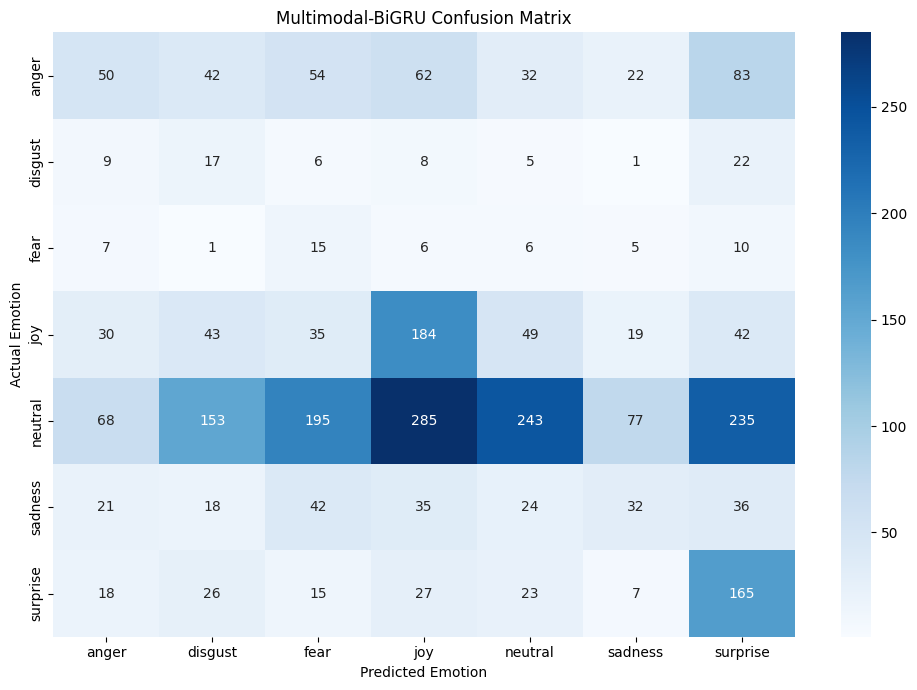

In [ ]:
# Plot multimodal confusion matrix

cm_multimodal = confusion_matrix(
    y_multimodal_test,
    y_multimodal_pred
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm_multimodal,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=EMOTIONS,
    yticklabels=EMOTIONS
)

plt.title("Multimodal-BiGRU Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.show()

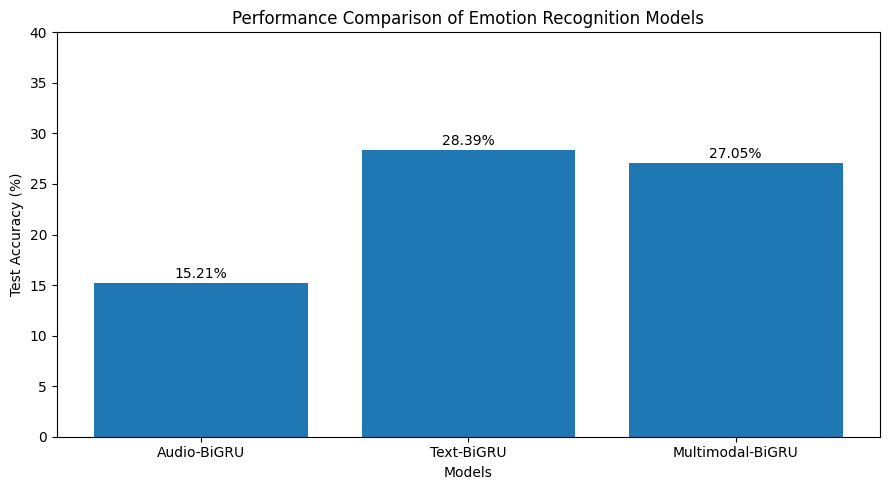

In [ ]:
# Compare test accuracy of all three models

model_names = [
    "Audio-BiGRU",
    "Text-BiGRU",
    "Multimodal-BiGRU"
]

model_accuracies = [
    15.21,
    28.39,
    27.05
]

plt.figure(figsize=(9, 5))

bars = plt.bar(model_names, model_accuracies)

plt.title("Performance Comparison of Emotion Recognition Models")
plt.xlabel("Models")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 40)

for bar, accuracy in zip(bars, model_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

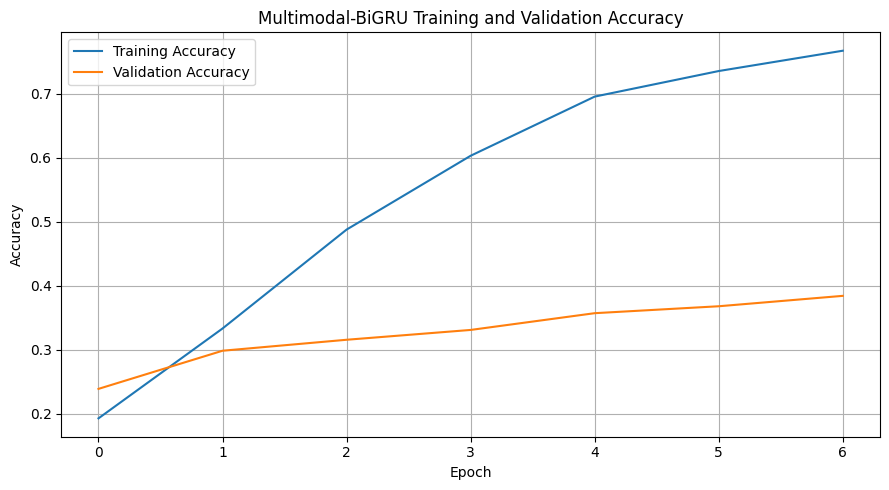

In [ ]:
# Plot multimodal training and validation accuracy

plt.figure(figsize=(9, 5))

plt.plot(
    multimodal_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    multimodal_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Multimodal-BiGRU Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

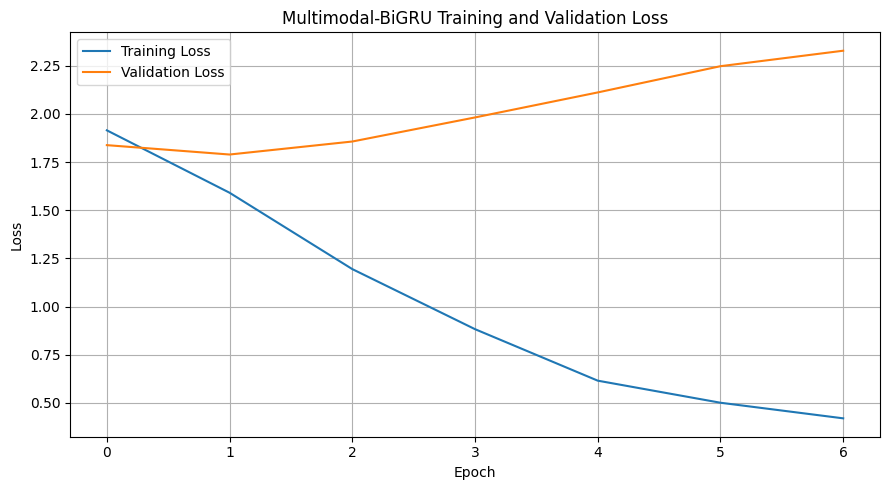

In [ ]:
# Plot multimodal training and validation loss

plt.figure(figsize=(9, 5))

plt.plot(
    multimodal_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    multimodal_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Multimodal-BiGRU Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Calculate evaluation metrics for all three models

audio_metrics = {
    "Accuracy": accuracy_score(y_audio_test, y_audio_pred),
    "Precision": precision_score(
        y_audio_test, y_audio_pred,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_audio_test, y_audio_pred,
        average="macro", zero_division=0
    ),
    "F1-Score": f1_score(
        y_audio_test, y_audio_pred,
        average="macro", zero_division=0
    )
}

text_metrics = {
    "Accuracy": accuracy_score(y_text_test, y_text_pred),
    "Precision": precision_score(
        y_text_test, y_text_pred,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_text_test, y_text_pred,
        average="macro", zero_division=0
    ),
    "F1-Score": f1_score(
        y_text_test, y_text_pred,
        average="macro", zero_division=0
    )
}

multimodal_metrics = {
    "Accuracy": accuracy_score(
        y_multimodal_test, y_multimodal_pred
    ),
    "Precision": precision_score(
        y_multimodal_test, y_multimodal_pred,
        average="macro", zero_division=0
    ),
    "Recall": recall_score(
        y_multimodal_test, y_multimodal_pred,
        average="macro", zero_division=0
    ),
    "F1-Score": f1_score(
        y_multimodal_test, y_multimodal_pred,
        average="macro", zero_division=0
    )
}

comparison_df = pd.DataFrame(
    {
        "Audio-BiGRU": audio_metrics,
        "Text-BiGRU": text_metrics,
        "Multimodal-BiGRU": multimodal_metrics
    }
)

print("Model Performance Comparison")
display(comparison_df.round(4))

Model Performance Comparison


,Audio-BiGRU,Text-BiGRU,Multimodal-BiGRU
Accuracy,0.1521,0.2839,0.2705
Precision,0.1670,0.2667,0.2512
Recall,0.1809,0.3032,0.2982
F1-Score,0.1270,0.2435,0.2227


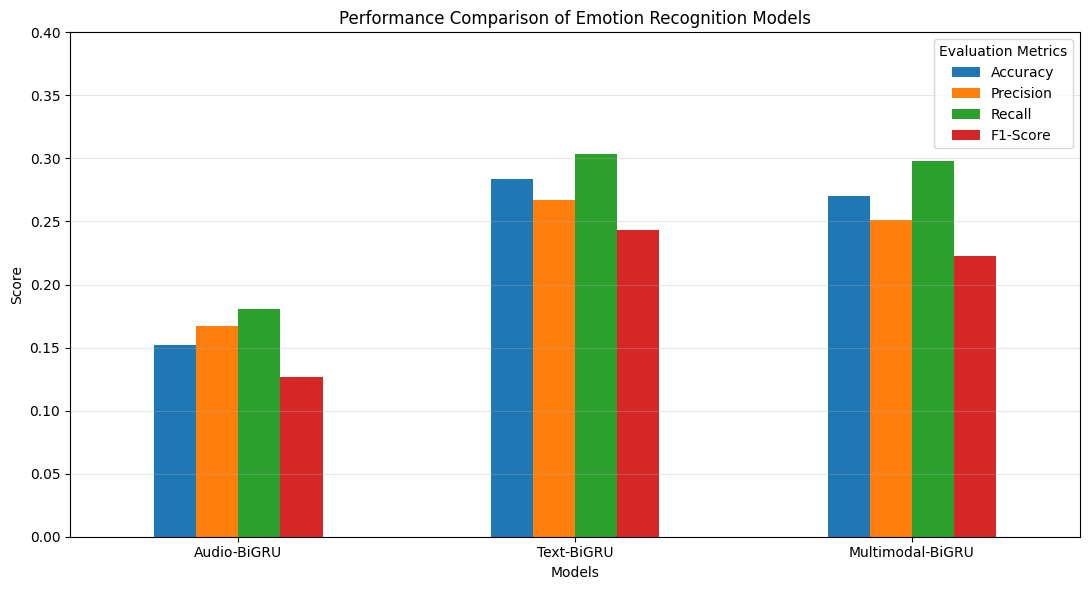

In [ ]:
# Visual comparison of model performance

comparison_df.T.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison of Emotion Recognition Models")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 0.4)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Save all three trained models

audio_model.save("/content/MELD/Audio_BiGRU.keras")

text_model.save("/content/MELD/Text_BiGRU.keras")

multimodal_model.save("/content/MELD/Multimodal_BiGRU.keras")

print("All three models saved successfully!")

print("\nSaved model files:")
print("1. Audio_BiGRU.keras")
print("2. Text_BiGRU.keras")
print("3. Multimodal_BiGRU.keras")

All three models saved successfully!

Saved model files:
1. Audio_BiGRU.keras
2. Text_BiGRU.keras
3. Multimodal_BiGRU.keras


In [ ]:
import json

# Save tokenizer
tokenizer_json = tokenizer.to_json()

with open("/content/MELD/tokenizer.json", "w") as file:
    file.write(tokenizer_json)

# Save emotion labels
with open("/content/MELD/emotion_labels.json", "w") as file:
    json.dump(emotion_to_id, file, indent=4)

print("Tokenizer saved successfully!")
print("Emotion label mapping saved successfully!")

Tokenizer saved successfully!
Emotion label mapping saved successfully!


In [ ]:
# Verify saved project files

saved_files = [
    "Audio_BiGRU.keras",
    "Text_BiGRU.keras",
    "Multimodal_BiGRU.keras",
    "tokenizer.json",
    "emotion_labels.json"
]

print("Checking saved project files:\n")

for filename in saved_files:
    file_path = Path("/content/MELD") / filename

    if file_path.exists():
        size_mb = file_path.stat().st_size / (1024 * 1024)
        print(f"{filename} - Available ({size_mb:.2f} MB)")
    else:
        print(f"{filename} - Missing")

Checking saved project files:

Audio_BiGRU.keras - Available (0.61 MB)
Text_BiGRU.keras - Available (15.65 MB)
Multimodal_BiGRU.keras - Available (16.43 MB)
tokenizer.json - Available (0.49 MB)
emotion_labels.json - Available (0.00 MB)


In [ ]:
# Create a folder for final project results

RESULTS_DIR = Path("/content/MELD/Final_Results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save model comparison table
comparison_df.to_csv(
    RESULTS_DIR / "model_performance_comparison.csv"
)

# Save emotion labels
with open(RESULTS_DIR / "emotion_labels.json", "w") as file:
    json.dump(emotion_to_id, file, indent=4)

print("Final results folder created successfully!")
print("Model comparison table saved!")
print("Emotion labels saved!")
print("\nResults folder:", RESULTS_DIR)

Final results folder created successfully!
Model comparison table saved!
Emotion labels saved!

Results folder: /content/MELD/Final_Results


In [ ]:
# Generate classification reports

audio_report = classification_report(
    y_audio_test,
    y_audio_pred,
    target_names=EMOTIONS,
    output_dict=True,
    zero_division=0
)

text_report = classification_report(
    y_text_test,
    y_text_pred,
    target_names=EMOTIONS,
    output_dict=True,
    zero_division=0
)

multimodal_report = classification_report(
    y_multimodal_test,
    y_multimodal_pred,
    target_names=EMOTIONS,
    output_dict=True,
    zero_division=0
)

# Save all reports together

all_reports = {
    "Audio-BiGRU": audio_report,
    "Text-BiGRU": text_report,
    "Multimodal-BiGRU": multimodal_report
}

with open(RESULTS_DIR / "classification_reports.json", "w") as file:
    json.dump(all_reports, file, indent=4)

print("Classification reports saved successfully!")

Classification reports saved successfully!


In [ ]:
# Generate confusion matrices

audio_cm = confusion_matrix(
    y_audio_test, y_audio_pred,
    labels=range(len(EMOTIONS))
)

text_cm = confusion_matrix(
    y_text_test, y_text_pred,
    labels=range(len(EMOTIONS))
)

multimodal_cm = confusion_matrix(
    y_multimodal_test, y_multimodal_pred,
    labels=range(len(EMOTIONS))
)

# Save confusion matrices as CSV files

pd.DataFrame(
    audio_cm, index=EMOTIONS, columns=EMOTIONS
).to_csv(RESULTS_DIR / "audio_confusion_matrix.csv")

pd.DataFrame(
    text_cm, index=EMOTIONS, columns=EMOTIONS
).to_csv(RESULTS_DIR / "text_confusion_matrix.csv")

pd.DataFrame(
    multimodal_cm, index=EMOTIONS, columns=EMOTIONS
).to_csv(RESULTS_DIR / "multimodal_confusion_matrix.csv")

print("All three confusion matrices saved successfully!")

All three confusion matrices saved successfully!


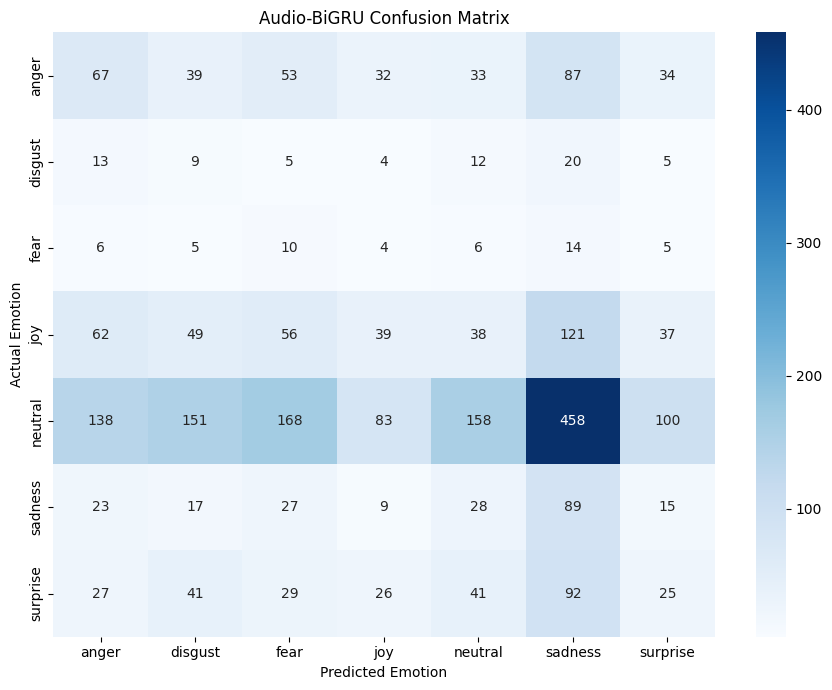

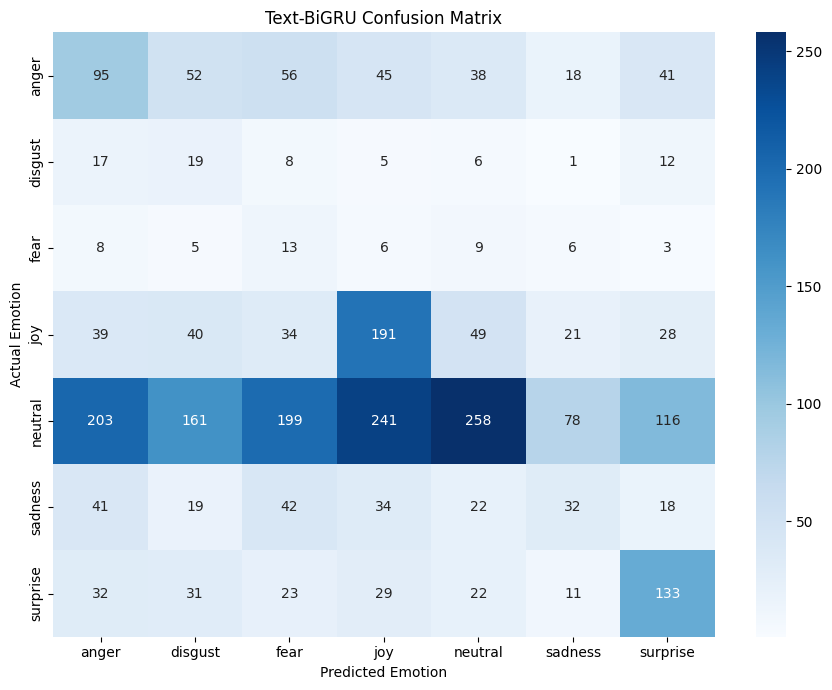

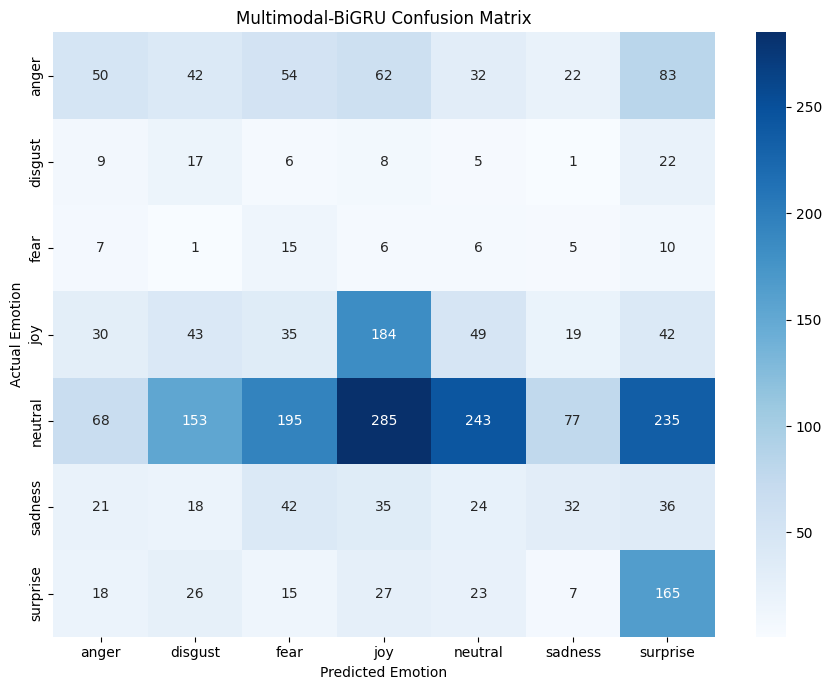

All confusion matrix images saved successfully!


In [ ]:
# Function to plot and save a confusion matrix

def save_confusion_matrix(cm, model_name, filename):

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=EMOTIONS,
        yticklabels=EMOTIONS
    )

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted Emotion")
    plt.ylabel("Actual Emotion")
    plt.tight_layout()

    plt.savefig(
        RESULTS_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# Save all three confusion matrix images

save_confusion_matrix(
    audio_cm, "Audio-BiGRU",
    "audio_confusion_matrix.png"
)

save_confusion_matrix(
    text_cm, "Text-BiGRU",
    "text_confusion_matrix.png"
)

save_confusion_matrix(
    multimodal_cm, "Multimodal-BiGRU",
    "multimodal_confusion_matrix.png"
)

print("All confusion matrix images saved successfully!")

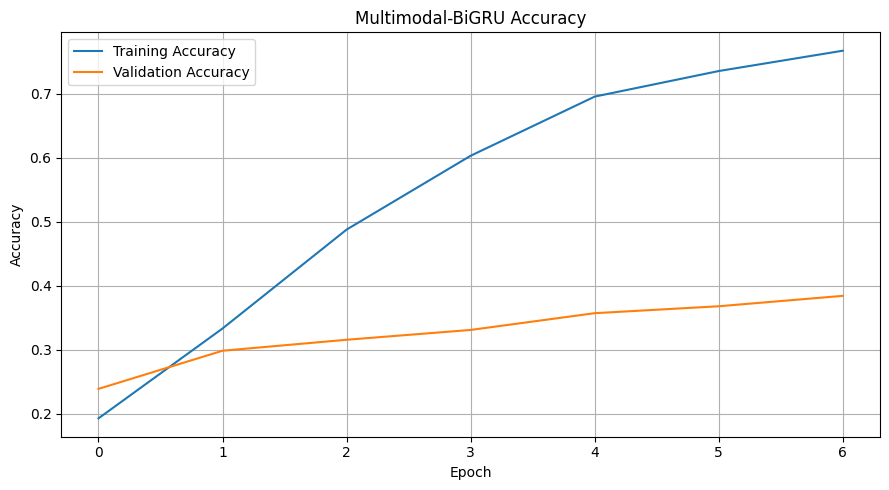

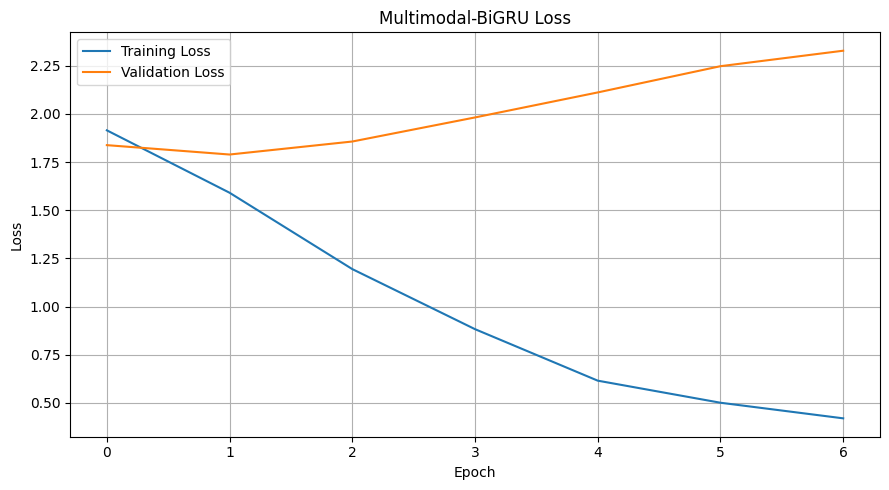

Multimodal training graphs saved successfully!


In [ ]:
# Save multimodal training accuracy graph

plt.figure(figsize=(9, 5))

plt.plot(
    multimodal_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    multimodal_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Multimodal-BiGRU Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "multimodal_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# Save multimodal training loss graph

plt.figure(figsize=(9, 5))

plt.plot(
    multimodal_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    multimodal_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Multimodal-BiGRU Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "multimodal_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Multimodal training graphs saved successfully!")

In [ ]:
# Create a ZIP archive containing project files

import shutil

PROJECT_DIR = Path("/content/MELD")
ZIP_PATH = "/content/MELD_Final_Project_Results.zip"

shutil.make_archive(
    "/content/MELD_Final_Project_Results",
    "zip",
    root_dir=PROJECT_DIR,
    base_dir="Final_Results"
)

print("Project results ZIP created successfully!")
print("ZIP file:", ZIP_PATH)

zip_size = Path(ZIP_PATH).stat().st_size / (1024 * 1024)
print(f"ZIP size: {zip_size:.2f} MB")

Project results ZIP created successfully!
ZIP file: /content/MELD_Final_Project_Results.zip
ZIP size: 0.69 MB


In [ ]:
import zipfile

COMPLETE_ZIP_PATH = "/content/MELD_Complete_Project.zip"

with zipfile.ZipFile(
    COMPLETE_ZIP_PATH, "w", zipfile.ZIP_DEFLATED
) as zip_file:

    # Add trained models
    for filename in [
        "Audio_BiGRU.keras",
        "Text_BiGRU.keras",
        "Multimodal_BiGRU.keras",
        "tokenizer.json",
        "emotion_labels.json"
    ]:
        file_path = PROJECT_DIR / filename
        zip_file.write(file_path, arcname=filename)

    # Add final results folder
    for file_path in RESULTS_DIR.rglob("*"):
        if file_path.is_file():
            arcname = str(Path("Final_Results") / file_path.relative_to(RESULTS_DIR))
            zip_file.write(file_path, arcname=arcname)

print("Complete project ZIP created successfully!")

zip_size = Path(COMPLETE_ZIP_PATH).stat().st_size / (1024 * 1024)
print(f"Complete project ZIP size: {zip_size:.2f} MB")

Complete project ZIP created successfully!
Complete project ZIP size: 23.88 MB


In [ ]:
from google.colab import files

files.download("/content/MELD_Complete_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Check whether the required data and model variables are available

required_variables = [
    "multimodal_model",
    "X_multimodal_text_train",
    "X_multimodal_audio_train",
    "y_multimodal_train",
    "X_multimodal_text_val",
    "X_multimodal_audio_val",
    "y_multimodal_val",
    "X_multimodal_text_test",
    "X_multimodal_audio_test",
    "y_multimodal_test",
    "EMOTIONS"
]

for variable in required_variables:
    print(variable, ":", "Available" if variable in globals() else "Missing")

print("\nGPU:", tf.config.list_physical_devices("GPU"))

multimodal_model : Available
X_multimodal_text_train : Available
X_multimodal_audio_train : Available
y_multimodal_train : Available
X_multimodal_text_val : Available
X_multimodal_audio_val : Available
y_multimodal_val : Available
X_multimodal_text_test : Available
X_multimodal_audio_test : Available
y_multimodal_test : Available
EMOTIONS : Available

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from tensorflow.keras import regularizers

# Text input branch
text_input = tf.keras.layers.Input(
    shape=(MAX_TEXT_LENGTH,),
    name="text_input"
)

text_features = tf.keras.layers.Embedding(
    input_dim=MAX_WORDS,
    output_dim=64,
    mask_zero=True
)(text_input)

text_features = tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(32, use_cudnn=False)
)(text_features)

# Audio input branch
audio_input = tf.keras.layers.Input(
    shape=(MAX_AUDIO_LENGTH, N_MFCC),
    name="audio_input"
)

audio_features = tf.keras.layers.Masking(
    mask_value=0.0
)(audio_input)

audio_features = tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(32)
)(audio_features)

# Combine text and audio features
combined_features = tf.keras.layers.Concatenate()(
    [text_features, audio_features]
)

x = tf.keras.layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.001)
)(combined_features)

x = tf.keras.layers.Dropout(0.5)(x)

output = tf.keras.layers.Dense(
    len(EMOTIONS),
    activation="softmax"
)(x)

# Create a separate tuned model
tuned_model = tf.keras.Model(
    inputs=[text_input, audio_input],
    outputs=output,
    name="Tuned_Multimodal_BiGRU"
)

# Compile
tuned_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

tuned_model.summary()

Model: "Tuned_Multimodal_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio_input         │ (None, 200, 40)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_6         │ (None, 200, 40)   │          0 │ audio_input[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 50, 64)    │    640,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_5         │ (None, 50)        │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking_2 (Masking) │ (None, 200, 40)   │          0 │ audio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any_2 (Any)         │ (None, 200)       │          0 │ not_equal_6[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_5     │ (None, 64)        │     18,816 │ embedding_3[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_5[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_6     │ (None, 64)        │     14,208 │ masking_2[0][0],  │
│ (Bidirectional)     │                   │            │ any_2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128)       │          0 │ bidirectional_5[… │
│ (Concatenate)       │                   │            │ bidirectional_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 64)        │      8,256 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 64)        │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 7)         │        455 │ dropout_4[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 681,735 (2.60 MB)

 Trainable params: 681,735 (2.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
tuned_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/content/MELD/Tuned_Multimodal_BiGRU.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

tuned_history = tuned_model.fit(
    [
        X_multimodal_text_train,
        X_multimodal_audio_train
    ],
    y_multimodal_train,

    validation_data=(
        [
            X_multimodal_text_val,
            X_multimodal_audio_val
        ],
        y_multimodal_val
    ),

    epochs=30,
    batch_size=32,
    callbacks=tuned_callbacks,
    verbose=1
)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step - accuracy: 0.3140 - loss: 1.8715
Epoch 1: val_loss improved from None to 1.70314, saving model to /content/MELD/Tuned_Multimodal_BiGRU.keras

Epoch 1: finished saving model to /content/MELD/Tuned_Multimodal_BiGRU.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 89s 266ms/step - accuracy: 0.3961 - loss: 1.7696 - val_accuracy: 0.4215 - val_loss: 1.7031 - learning_rate: 3.0000e-04
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - accuracy: 0.4737 - loss: 1.6207
Epoch 2: val_loss improved from 1.70314 to 1.63802, saving model to /content/MELD/Tuned_Multimodal_BiGRU.keras

Epoch 2: finished saving model to /content/MELD/Tuned_Multimodal_BiGRU.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 76s 243ms/step - accuracy: 0.4758 - loss: 1.6079 - val_accuracy: 0.4395 - val_loss: 1.6380 - learning_rate: 3.0000e-04
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 239ms/step - accuracy: 0.5031 - loss: 1.5087
Epoch 3: val_loss improved from 1.63802 to 1.61457, saving model 

In [ ]:
# Evaluate tuned model on test data

tuned_test_loss, tuned_test_accuracy = tuned_model.evaluate(
    [
        X_multimodal_text_test,
        X_multimodal_audio_test
    ],
    y_multimodal_test,
    verbose=1
)

# Generate predictions
tuned_predictions = tuned_model.predict(
    [
        X_multimodal_text_test,
        X_multimodal_audio_test
    ],
    verbose=1
)

y_tuned_pred = np.argmax(tuned_predictions, axis=1)

# Print test accuracy
print("\nTuned Multimodal-BiGRU Test Results")
print("-----------------------------------")
print("Test Loss:", round(tuned_test_loss, 4))
print("Test Accuracy:", round(tuned_test_accuracy * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_multimodal_test,
    y_tuned_pred,
    target_names=EMOTIONS,
    digits=4,
    zero_division=0
))

82/82 ━━━━━━━━━━━━━━━━━━━━ 8s 102ms/step - accuracy: 0.5000 - loss: 1.5287
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step

Tuned Multimodal-BiGRU Test Results
-----------------------------------
Test Loss: 1.5287
Test Accuracy: 50.0 %

Classification Report:
              precision    recall  f1-score   support

       anger     0.5000    0.0087    0.0171       345
     disgust     0.0000    0.0000    0.0000        68
        fear     0.0000    0.0000    0.0000        50
         joy     0.1625    0.0323    0.0539       402
     neutral     0.5273    0.9291    0.6728      1256
     sadness     0.3333    0.0048    0.0095       208
    surprise     0.3929    0.4306    0.4109       281

    accuracy                         0.5000      2610
   macro avg     0.2737    0.2008    0.1663      2610
weighted avg     0.4138    0.5000    0.3793      2610



In [ ]:
from sklearn.utils.class_weight import compute_class_weight

# Calculate class weights from training labels
classes = np.unique(y_multimodal_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_multimodal_train
)

tuned_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weights)
}

print("Class weights:")
for class_id, weight in tuned_class_weights.items():
    print(EMOTIONS[class_id], ":", round(weight, 3))

# Create a fresh model with the same tuned architecture
balanced_model = tf.keras.models.clone_model(tuned_model)

balanced_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Separate callbacks and checkpoint
balanced_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/content/MELD/Tuned_Multimodal_BiGRU_ClassWeighted.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# Train with class weights
balanced_history = balanced_model.fit(
    [
        X_multimodal_text_train,
        X_multimodal_audio_train
    ],
    y_multimodal_train,

    validation_data=(
        [
            X_multimodal_text_val,
            X_multimodal_audio_val
        ],
        y_multimodal_val
    ),

    epochs=30,
    batch_size=32,
    class_weight=tuned_class_weights,
    callbacks=balanced_callbacks,
    verbose=1
)

Class weights:
anger : 1.287
disgust : 5.265
fear : 5.324
joy : 0.819
neutral : 0.303
sadness : 2.089
surprise : 1.184
Epoch 1/30
230/313 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.1499 - loss: 2.1071

InvalidArgumentError: Graph execution error:

Detected at node Tuned_Multimodal_BiGRU_1/bidirectional_5_1/forward_gru_5_1/Assert/Assert defined at (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py", line 37, in <module>

  File "/usr/local/lib/python3.13/dist-packages/traitlets/config/application.py", line 992, in launch_instance

  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelapp.py", line 712, in start

  File "/usr/local/lib/python3.13/dist-packages/tornado/platform/asyncio.py", line 203, in start

  File "/usr/lib/python3.13/asyncio/base_events.py", line 684, in run_forever

  File "/usr/lib/python3.13/asyncio/base_events.py", line 2061, in _run_once

  File "/usr/lib/python3.13/asyncio/events.py", line 89, in _run

  File "/usr/local/lib/python3.13/dist-packages/ipykernel/kernelbase.py", line 510, in dispatch_qu

In [ ]:
# Rebuild the balanced model with cuDNN disabled for text GRU

text_input = tf.keras.layers.Input(
    shape=(MAX_TEXT_LENGTH,),
    name="text_input"
)

text_features = tf.keras.layers.Embedding(
    input_dim=MAX_WORDS,
    output_dim=64,
    mask_zero=True
)(text_input)

text_features = tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(32, use_cudnn=False)
)(text_features)

audio_input = tf.keras.layers.Input(
    shape=(MAX_AUDIO_LENGTH, N_MFCC),
    name="audio_input"
)

audio_features = tf.keras.layers.Masking(
    mask_value=0.0
)(audio_input)

audio_features = tf.keras.layers.Bidirectional(
    tf.keras.layers.GRU(32)
)(audio_features)

combined_features = tf.keras.layers.Concatenate()(
    [text_features, audio_features]
)

x = tf.keras.layers.Dense(
    64,
    activation="relu",
    kernel_regularizer=regularizers.l2(0.001)
)(combined_features)

x = tf.keras.layers.Dropout(0.5)(x)

output = tf.keras.layers.Dense(
    len(EMOTIONS),
    activation="softmax"
)(x)

balanced_model = tf.keras.Model(
    inputs=[text_input, audio_input],
    outputs=output,
    name="Balanced_Multimodal_BiGRU"
)

balanced_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Balanced model rebuilt successfully!")
balanced_model.summary()

Balanced model rebuilt successfully!


Model: "Balanced_Multimodal_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio_input         │ (None, 200, 40)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_10        │ (None, 200, 40)   │          0 │ audio_input[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_4         │ (None, 50, 64)    │    640,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_9         │ (None, 50)        │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking_3 (Masking) │ (None, 200, 40)   │          0 │ audio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any_4 (Any)         │ (None, 200)       │          0 │ not_equal_10[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_7     │ (None, 64)        │     18,816 │ embedding_4[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_9[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_8     │ (None, 64)        │     14,208 │ masking_3[0][0],  │
│ (Bidirectional)     │                   │            │ any_4[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 128)       │          0 │ bidirectional_7[… │
│ (Concatenate)       │                   │            │ bidirectional_8[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 64)        │      8,256 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64)        │          0 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 7)         │        455 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 681,735 (2.60 MB)

 Trainable params: 681,735 (2.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
balanced_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/content/MELD/Tuned_Multimodal_BiGRU_ClassWeighted.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

balanced_history = balanced_model.fit(
    [
        X_multimodal_text_train,
        X_multimodal_audio_train
    ],
    y_multimodal_train,

    validation_data=(
        [
            X_multimodal_text_val,
            X_multimodal_audio_val
        ],
        y_multimodal_val
    ),

    epochs=30,
    batch_size=32,
    class_weight=tuned_class_weights,
    callbacks=balanced_callbacks,
    verbose=1
)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 240ms/step - accuracy: 0.1663 - loss: 2.1076
Epoch 1: val_loss improved from None to 2.02887, saving model to /content/MELD/Tuned_Multimodal_BiGRU_ClassWeighted.keras

Epoch 1: finished saving model to /content/MELD/Tuned_Multimodal_BiGRU_ClassWeighted.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 85s 251ms/step - accuracy: 0.1679 - loss: 2.0927 - val_accuracy: 0.1354 - val_loss: 2.0289 - learning_rate: 3.0000e-04
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 246ms/step - accuracy: 0.1663 - loss: 2.0070
Epoch 2: val_loss improved from 2.02887 to 2.02058, saving model to /content/MELD/Tuned_Multimodal_BiGRU_ClassWeighted.keras

Epoch 2: finished saving model to /content/MELD/Tuned_Multimodal_BiGRU_ClassWeighted.keras
313/313 ━━━━━━━━━━━━━━━━━━━━ 79s 253ms/step - accuracy: 0.1622 - loss: 2.0154 - val_accuracy: 0.1489 - val_loss: 2.0206 - learning_rate: 3.0000e-04
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 245ms/step - accuracy: 0.1808 - loss: 1.9521
Epoch 3: 

In [ ]:
import os

print("Checking previous project files...\n")

paths = [
    "/content/MELD",
    "/content/MELD/MELD.Raw",
    "/content/MELD/Final_Results",
    "/content/MELD/Tuned_Multimodal_BiGRU.keras",
    "/content/MELD_Complete_Project.zip"
]

for path in paths:
    print(path, ":", "Available" if os.path.exists(path) else "Not found")

print("\nChecking important variables...")

variables = [
    "balanced_model",
    "tuned_model",
    "X_multimodal_text_train",
    "X_multimodal_audio_train",
    "y_multimodal_train",
    "EMOTIONS"
]

for variable in variables:
    print(variable, ":", "Available" if variable in globals() else "Not available")

Checking previous project files...

/content/MELD : Available
/content/MELD/MELD.Raw : Available
/content/MELD/Final_Results : Available
/content/MELD/Tuned_Multimodal_BiGRU.keras : Available
/content/MELD_Complete_Project.zip : Available

Checking important variables...
balanced_model : Available
tuned_model : Available
X_multimodal_text_train : Available
X_multimodal_audio_train : Available
y_multimodal_train : Available
EMOTIONS : Available


In [ ]:
# Evaluate balanced model on test dataset

balanced_test_loss, balanced_test_accuracy = balanced_model.evaluate(
    [
        X_multimodal_text_test,
        X_multimodal_audio_test
    ],
    y_multimodal_test,
    verbose=1
)

# Generate predictions
balanced_predictions = balanced_model.predict(
    [
        X_multimodal_text_test,
        X_multimodal_audio_test
    ],
    verbose=1
)

y_balanced_pred = np.argmax(balanced_predictions, axis=1)

# Display results
print("\nClass-Weighted Multimodal-BiGRU Results")
print("---------------------------------------")
print("Test Loss:", round(balanced_test_loss, 4))
print("Test Accuracy:", round(balanced_test_accuracy * 100, 2), "%")

print("\nClassification Report:")

print(classification_report(
    y_multimodal_test,
    y_balanced_pred,
    target_names=EMOTIONS,
    digits=4,
    zero_division=0
))

82/82 ━━━━━━━━━━━━━━━━━━━━ 16s 193ms/step - accuracy: 0.2847 - loss: 1.8277
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step

Class-Weighted Multimodal-BiGRU Results
---------------------------------------
Test Loss: 1.8277
Test Accuracy: 28.47 %

Classification Report:
              precision    recall  f1-score   support

       anger     0.2133    0.1391    0.1684       345
     disgust     0.0296    0.1618    0.0501        68
        fear     0.0417    0.2000    0.0690        50
         joy     0.2829    0.4652    0.3518       402
     neutral     0.5805    0.2611    0.3602      1256
     sadness     0.1810    0.0913    0.1214       208
    surprise     0.3160    0.4982    0.3867       281

    accuracy                         0.2847      2610
   macro avg     0.2350    0.2595    0.2154      2610
weighted avg     0.4012    0.2847    0.3038      2610



In [ ]:
experiment_predictions = {
    "Audio-BiGRU": (y_audio_test, y_audio_pred),
    "Text-BiGRU": (y_text_test, y_text_pred),
    "Original Multimodal-BiGRU": (
        y_multimodal_test, y_multimodal_pred
    ),
    "Tuned Multimodal-BiGRU": (
        y_multimodal_test, y_tuned_pred
    ),
    "Class-Weighted Multimodal-BiGRU": (
        y_multimodal_test, y_balanced_pred
    )
}

comparison_results = []

for model_name, (actual, predicted) in experiment_predictions.items():

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(actual, predicted),
        "Macro Precision": precision_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            actual, predicted, average="weighted", zero_division=0
        )
    })

experiment_comparison_df = pd.DataFrame(comparison_results)

print(experiment_comparison_df.round(4).to_string(index=False))

# Save comparison
experiment_comparison_df.to_csv(
    "/content/MELD/Final_Results/experiment_comparison.csv",
    index=False
)

print("\nExperiment comparison saved successfully!")

                          Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
                    Audio-BiGRU    0.1521           0.1670        0.1809    0.1270       0.1688
                     Text-BiGRU    0.2839           0.2667        0.3032    0.2435       0.3061
      Original Multimodal-BiGRU    0.2705           0.2512        0.2982    0.2227       0.2813
         Tuned Multimodal-BiGRU    0.5000           0.2737        0.2008    0.1663       0.3793
Class-Weighted Multimodal-BiGRU    0.2847           0.2350        0.2595    0.2154       0.3038

Experiment comparison saved successfully!


In [ ]:
import os
import shutil

experiment_folder = "/content/MELD/Improved_Experiments"

os.makedirs(experiment_folder, exist_ok=True)

# Save the unweighted tuned model
tuned_model.save(
    os.path.join(experiment_folder, "Tuned_Multimodal_BiGRU.keras")
)

# Save the class-weighted model
balanced_model.save(
    os.path.join(experiment_folder, "ClassWeighted_Multimodal_BiGRU.keras")
)

# Save the experiment comparison table
shutil.copy2(
    "/content/MELD/Final_Results/experiment_comparison.csv",
    os.path.join(experiment_folder, "experiment_comparison.csv")
)

print("Improved experiment files saved successfully!")
print("\nSaved files:")

for filename in os.listdir(experiment_folder):
    print("-", filename)

Improved experiment files saved successfully!

Saved files:
- Tuned_Multimodal_BiGRU.keras
- experiment_comparison.csv
- ClassWeighted_Multimodal_BiGRU.keras


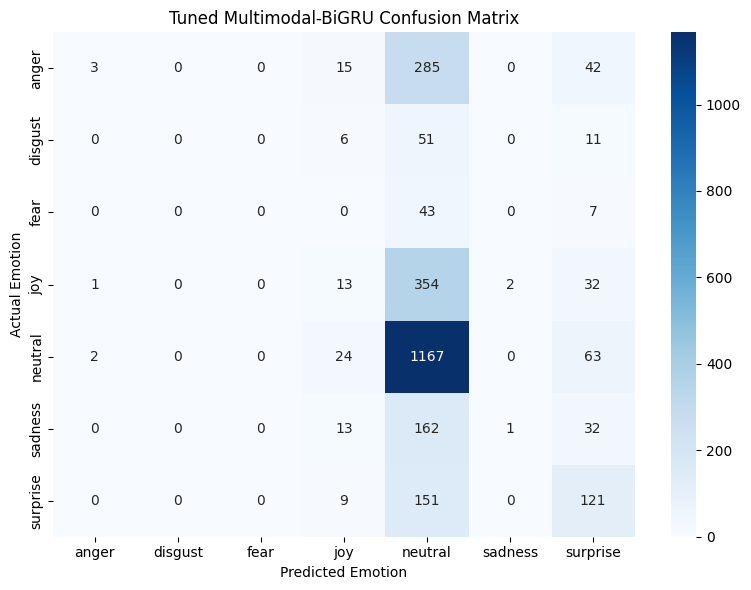

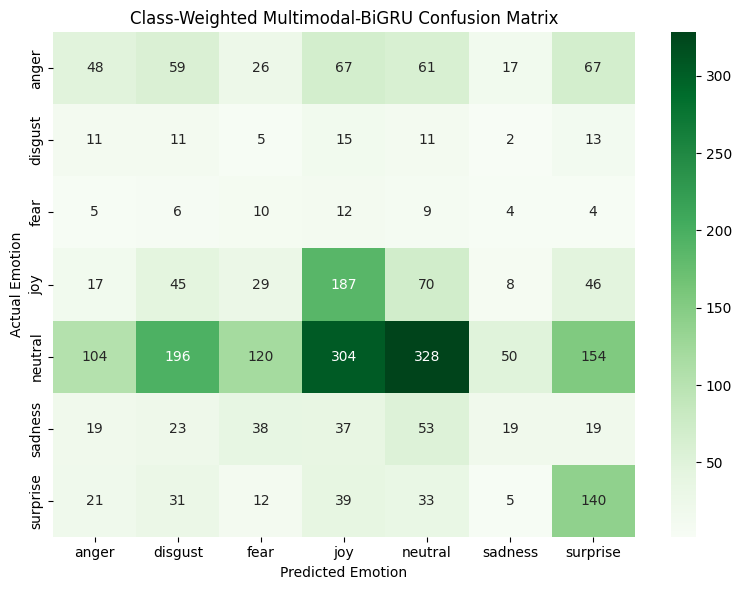

Both confusion matrices saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import os

experiment_dir = "/content/MELD/Improved_Experiments"
os.makedirs(experiment_dir, exist_ok=True)

# Confusion matrix for tuned multimodal model
cm_tuned = confusion_matrix(
    y_multimodal_test,
    y_tuned_pred
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=EMOTIONS,
    yticklabels=EMOTIONS
)

plt.title("Tuned Multimodal-BiGRU Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()

plt.savefig(
    experiment_dir + "/Tuned_Multimodal_Confusion_Matrix.png",
    dpi=300
)
plt.show()


# Confusion matrix for class-weighted multimodal model
cm_balanced = confusion_matrix(
    y_multimodal_test,
    y_balanced_pred
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=EMOTIONS,
    yticklabels=EMOTIONS
)

plt.title("Class-Weighted Multimodal-BiGRU Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()

plt.savefig(
    experiment_dir + "/ClassWeighted_Multimodal_Confusion_Matrix.png",
    dpi=300
)
plt.show()

print("Both confusion matrices saved successfully!")

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import os

experiment_dir = "/content/MELD/Improved_Experiments"

# Tuned model report
tuned_report = classification_report(
    y_multimodal_test,
    y_tuned_pred,
    target_names=EMOTIONS,
    output_dict=True,
    zero_division=0
)

tuned_report_df = pd.DataFrame(tuned_report).transpose()

tuned_report_df.to_csv(
    experiment_dir + "/Tuned_Multimodal_Classification_Report.csv"
)

# Class-weighted model report
balanced_report = classification_report(
    y_multimodal_test,
    y_balanced_pred,
    target_names=EMOTIONS,
    output_dict=True,
    zero_division=0
)

balanced_report_df = pd.DataFrame(balanced_report).transpose()

balanced_report_df.to_csv(
    experiment_dir + "/ClassWeighted_Multimodal_Classification_Report.csv"
)

print("Classification reports saved successfully!")

print("\nTuned Multimodal-BiGRU:")
print(tuned_report_df.round(4))

print("\nClass-Weighted Multimodal-BiGRU:")
print(balanced_report_df.round(4))

Classification reports saved successfully!

Tuned Multimodal-BiGRU:
              precision  recall  f1-score  support
anger            0.5000  0.0087    0.0171    345.0
disgust          0.0000  0.0000    0.0000     68.0
fear             0.0000  0.0000    0.0000     50.0
joy              0.1625  0.0323    0.0539    402.0
neutral          0.5273  0.9291    0.6728   1256.0
sadness          0.3333  0.0048    0.0095    208.0
surprise         0.3929  0.4306    0.4109    281.0
accuracy         0.5000  0.5000    0.5000      0.5
macro avg        0.2737  0.2008    0.1663   2610.0
weighted avg     0.4138  0.5000    0.3793   2610.0

Class-Weighted Multimodal-BiGRU:
              precision  recall  f1-score    support
anger            0.2133  0.1391    0.1684   345.0000
disgust          0.0296  0.1618    0.0501    68.0000
fear             0.0417  0.2000    0.0690    50.0000
joy              0.2829  0.4652    0.3518   402.0000
neutral          0.5805  0.2611    0.3602  1256.0000
sadness          0.

In [ ]:
print("Available training histories:")

for name in ["history", "multimodal_history",
             "tuned_history", "balanced_history"]:

    if name in globals():
        print(name, "is available")
    else:
        print(name, "is not available")

Available training histories:
history is not available
multimodal_history is available
tuned_history is available
balanced_history is available


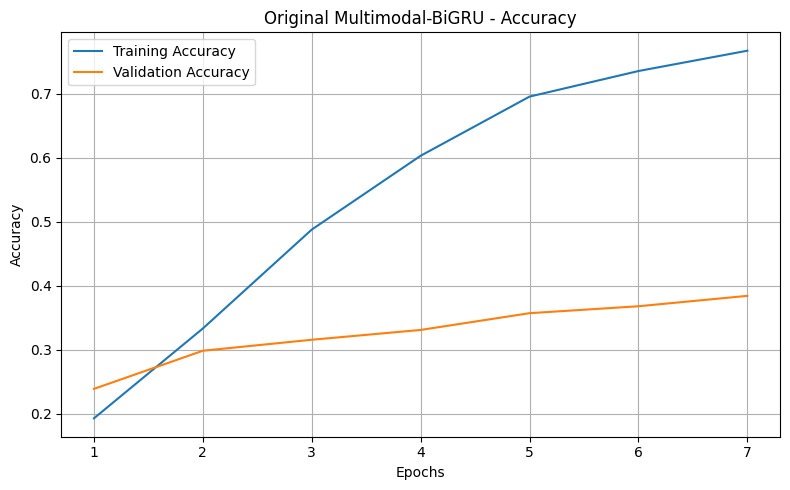

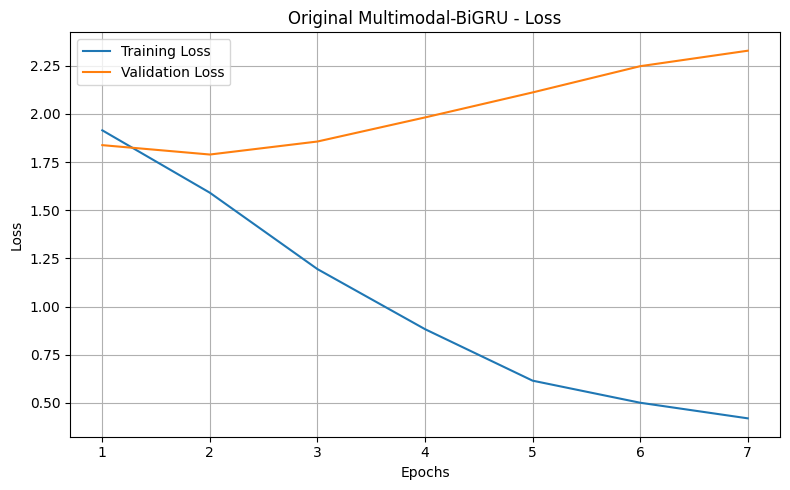

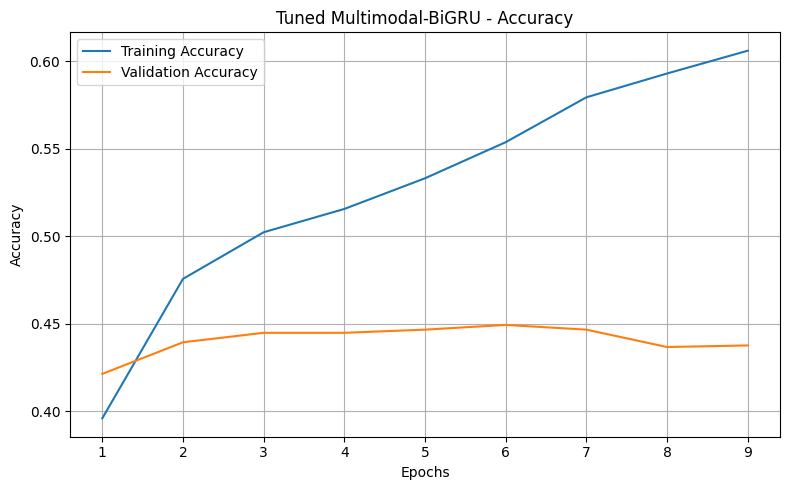

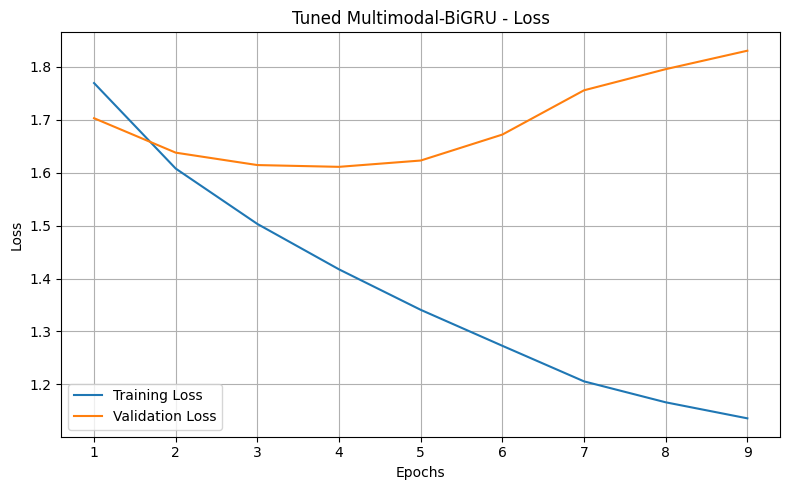

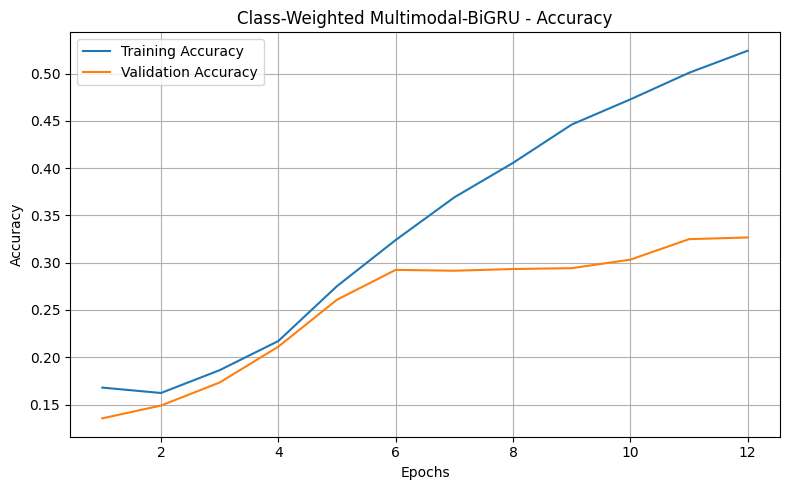

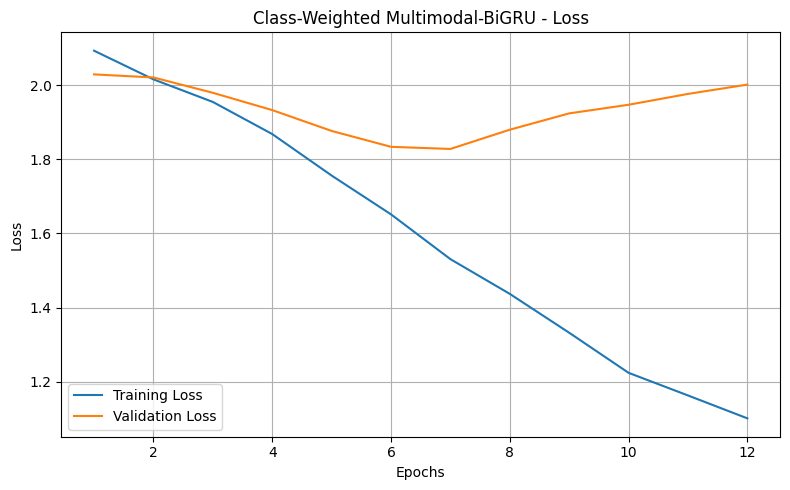

All training graphs saved successfully!


In [ ]:
import matplotlib.pyplot as plt
import os

experiment_dir = "/content/MELD/Improved_Experiments"

histories = {
    "Original Multimodal-BiGRU": multimodal_history,
    "Tuned Multimodal-BiGRU": tuned_history,
    "Class-Weighted Multimodal-BiGRU": balanced_history
}

for model_name, model_history in histories.items():

    history_data = model_history.history
    epochs = range(1, len(history_data["loss"]) + 1)

    # Accuracy graph
    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        history_data["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        epochs,
        history_data["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(model_name + " - Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    filename = model_name.replace(" ", "_").replace("-", "_")

    plt.savefig(
        experiment_dir + "/" + filename + "_Accuracy.png",
        dpi=300
    )

    plt.show()
    plt.close()

    # Loss graph
    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        history_data["loss"],
        label="Training Loss"
    )

    plt.plot(
        epochs,
        history_data["val_loss"],
        label="Validation Loss"
    )

    plt.title(model_name + " - Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        experiment_dir + "/" + filename + "_Loss.png",
        dpi=300
    )

    plt.show()
    plt.close()

print("All training graphs saved successfully!")

In [ ]:
import os

experiment_dir = "/content/MELD/Improved_Experiments"

print("IMPROVED EXPERIMENT FILES")
print("-" * 55)

for root, dirs, files in os.walk(experiment_dir):
    for file in sorted(files):
        file_path = os.path.join(root, file)
        size_mb = os.path.getsize(file_path) / (1024 * 1024)

        print(f"{file:<55} {size_mb:.2f} MB")

print("\nTotal files:", sum(
    len(files) for _, _, files in os.walk(experiment_dir)
))

print("\nExperiment directory verified!")

IMPROVED EXPERIMENT FILES
-------------------------------------------------------
ClassWeighted_Multimodal_BiGRU.keras                    7.87 MB
ClassWeighted_Multimodal_Classification_Report.csv      0.00 MB
ClassWeighted_Multimodal_Confusion_Matrix.png           0.19 MB
Class_Weighted_Multimodal_BiGRU_Accuracy.png            0.14 MB
Class_Weighted_Multimodal_BiGRU_Loss.png                0.13 MB
Original_Multimodal_BiGRU_Accuracy.png                  0.12 MB
Original_Multimodal_BiGRU_Loss.png                      0.13 MB
Tuned_Multimodal_BiGRU.keras                            7.87 MB
Tuned_Multimodal_BiGRU_Accuracy.png                     0.13 MB
Tuned_Multimodal_BiGRU_Loss.png                         0.13 MB
Tuned_Multimodal_Classification_Report.csv              0.00 MB
Tuned_Multimodal_Confusion_Matrix.png                   0.16 MB
experiment_comparison.csv                               0.00 MB

Total files: 13

Experiment directory verified!


In [ ]:
import shutil
import os

experiment_dir = "/content/MELD/Improved_Experiments"

zip_path = "/content/MELD_Improved_Experiments"

shutil.make_archive(
    zip_path,
    "zip",
    root_dir="/content/MELD",
    base_dir="Improved_Experiments"
)

final_zip = zip_path + ".zip"

size_mb = os.path.getsize(final_zip) / (1024 * 1024)

print("Improved experiments ZIP created successfully!")
print("ZIP file:", final_zip)
print("ZIP size:", round(size_mb, 2), "MB")

Improved experiments ZIP created successfully!
ZIP file: /content/MELD_Improved_Experiments.zip
ZIP size: 11.88 MB


In [ ]:
from google.colab import files

files.download("/content/MELD_Improved_Experiments.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("ORIGINAL MULTIMODAL MODEL")
print("-" * 45)

multimodal_model.summary()

print("\nINPUT SHAPES")
print("Text training:", X_multimodal_text_train.shape)
print("Audio training:", X_multimodal_audio_train.shape)

print("\nLABEL SHAPE:", y_multimodal_train.shape)

print("\nNUMBER OF EMOTIONS:", len(EMOTIONS))
print("EMOTIONS:", EMOTIONS)

ORIGINAL MULTIMODAL MODEL
---------------------------------------------


Model: "Multimodal_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio_input         │ (None, 200, 40)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 200, 40)   │          0 │ audio_input[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 50, 128)   │  1,280,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_3         │ (None, 50)        │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking_1 (Masking) │ (None, 200, 40)   │          0 │ audio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any_1 (Any)         │ (None, 200)       │          0 │ not_equal_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_3     │ (None, 128)       │     74,496 │ embedding_2[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_4     │ (None, 128)       │     40,704 │ masking_1[0][0],  │
│ (Bidirectional)     │                   │            │ any_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 256)       │          0 │ bidirectional_3[… │
│ (Concatenate)       │                   │            │ bidirectional_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │     32,896 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 128)       │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 7)         │        903 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 4,286,999 (16.35 MB)

 Trainable params: 1,428,999 (5.45 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,858,000 (10.90 MB)


INPUT SHAPES
Text training: (9988, 50)
Audio training: (9988, 200, 40)

LABEL SHAPE: (9988,)

NUMBER OF EMOTIONS: 7
EMOTIONS: ['anger', 'disgust', 'fear', 'joy', 'neutral', 'sadness', 'surprise']


In [ ]:
print("AVAILABLE MODEL VARIABLES")
print("-" * 40)

for name, value in globals().copy().items():
    if hasattr(value, "summary") and hasattr(value, "layers"):
        print("Model variable:", name)

AVAILABLE MODEL VARIABLES
----------------------------------------
Model variable: audio_model
Model variable: text_model
Model variable: multimodal_model
Model variable: tuned_model
Model variable: balanced_model


In [ ]:
print("VALIDATION DATA CHECK")
print("-" * 40)

variables_to_check = [
    "X_multimodal_text_val",
    "X_multimodal_audio_val",
    "y_multimodal_val",
    "X_multimodal_text_train",
    "X_multimodal_audio_train",
    "y_multimodal_train"
]

for name in variables_to_check:
    if name in globals():
        value = globals()[name]
        print(name, ":", value.shape)
    else:
        print(name, ": NOT AVAILABLE")

print("\nORIGINAL MODEL INPUTS:")
for layer in multimodal_model.inputs:
    print(layer.name, layer.shape)

VALIDATION DATA CHECK
----------------------------------------
X_multimodal_text_val : (1108, 50)
X_multimodal_audio_val : (1108, 200, 40)
y_multimodal_val : (1108,)
X_multimodal_text_train : (9988, 50)
X_multimodal_audio_train : (9988, 200, 40)
y_multimodal_train : (9988,)

ORIGINAL MODEL INPUTS:
text_input (None, 50)
audio_input (None, 200, 40)


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Input, Dense, Dropout, Concatenate,
    Softmax, Multiply, Lambda
)
from tensorflow.keras.models import Model

# Freeze the original model
multimodal_model.trainable = False

# Get trained text and audio representations
text_features = multimodal_model.get_layer(
    "bidirectional_3"
).output

audio_features = multimodal_model.get_layer(
    "bidirectional_4"
).output

# Calculate attention scores for both modalities
combined_features = Concatenate()([
    text_features,
    audio_features
])

attention_scores = Dense(
    2,
    activation=None,
    name="modality_attention_scores"
)(combined_features)

attention_weights = Softmax(
    axis=-1,
    name="modality_attention_weights"
)(attention_scores)

# Separate text and audio attention weights
text_weight = Lambda(
    lambda x: x[:, 0:1]
)(attention_weights)

audio_weight = Lambda(
    lambda x: x[:, 1:2]
)(attention_weights)

# Apply learned attention weights
weighted_text = Multiply()([
    text_features,
    text_weight
])

weighted_audio = Multiply()([
    audio_features,
    audio_weight
])

# Attention-based fusion
fused_features = Concatenate()([
    weighted_text,
    weighted_audio
])

# Classification layers
x = Dense(
    128,
    activation="relu"
)(fused_features)

x = Dropout(0.5)(x)

output = Dense(
    7,
    activation="softmax"
)(x)

attention_model = Model(
    inputs=multimodal_model.inputs,
    outputs=output,
    name="Attention_Multimodal_BiGRU"
)

attention_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Attention-based model created successfully!")
attention_model.summary()

Attention-based model created successfully!


Model: "Attention_Multimodal_BiGRU"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ audio_input         │ (None, 200, 40)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 50)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_4         │ (None, 200, 40)   │          0 │ audio_input[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 50, 128)   │  1,280,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_3         │ (None, 50)        │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ masking_1 (Masking) │ (None, 200, 40)   │          0 │ audio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any_1 (Any)         │ (None, 200)       │          0 │ not_equal_4[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_3     │ (None, 128)       │     74,496 │ embedding_2[0][0… │
│ (Bidirectional)     │                   │            │ not_equal_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_4     │ (None, 128)       │     40,704 │ masking_1[0][0],  │
│ (Bidirectional)     │                   │            │ any_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 256)       │          0 │ bidirectional_3[… │
│ (Concatenate)       │                   │            │ bidirectional_4[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ modality_attention… │ (None, 2)         │        514 │ concatenate_3[0]… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ modality_attention… │ (None, 2)         │          0 │ modality_attenti… │
│ (Softmax)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 1)         │          0 │ modality_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 1)         │          0 │ modality_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 128)       │          0 │ bidirectional_3[… │
│                     │                   │            │ lambda[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 128)       │          0 │ bidirectional_4[… │
│ (Multiply)          │                   │            │ lambda_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 256)       │          0 │ multiply[0][0],   │
│ (Concatenate)       │                   │            │ multiply_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 128)       │     32,896 │ concatenate_4[0]… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,429,513 (5.45 MB)

 Trainable params: 34,313 (134.04 KB)

 Non-trainable params: 1,395,200 (5.32 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

attention_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

attention_lr_scheduler = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

attention_history = attention_model.fit(
    [
        X_multimodal_audio_train,
        X_multimodal_text_train
    ],
    y_multimodal_train,
    validation_data=(
        [
            X_multimodal_audio_val,
            X_multimodal_text_val
        ],
        y_multimodal_val
    ),
    epochs=15,
    batch_size=32,
    callbacks=[
        attention_early_stopping,
        attention_lr_scheduler
    ],
    verbose=1
)

print("\nAttention model training completed!")

Epoch 1/15


ValueError: Input 0 with name 'text_input' of layer 'Attention_Multimodal_BiGRU' is incompatible with the layer: expected shape=(None, 50), found shape=(None, 200, 40)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

attention_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

attention_lr_scheduler = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001,
    verbose=1
)

attention_history = attention_model.fit(
    [
        X_multimodal_text_train,
        X_multimodal_audio_train
    ],
    y_multimodal_train,
    validation_data=(
        [
            X_multimodal_text_val,
            X_multimodal_audio_val
        ],
        y_multimodal_val
    ),
    epochs=15,
    batch_size=32,
    callbacks=[
        attention_early_stopping,
        attention_lr_scheduler
    ],
    verbose=1
)

print("\nAttention model training completed!")

Epoch 1/15


ValueError: Creating variables on a non-first call to a function decorated with tf.function.

In [ ]:
# Check the actual input order
print("MODEL INPUT ORDER:")
for i, layer in enumerate(attention_model.inputs):
    print(i, layer.name, layer.shape)

# Recompile using eager execution
attention_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0003
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    run_eagerly=True
)

print("\nModel recompiled with eager execution.")

# Train using the verified input order
attention_history = attention_model.fit(
    [
        X_multimodal_text_train,
        X_multimodal_audio_train
    ],
    y_multimodal_train,
    validation_data=(
        [
            X_multimodal_text_val,
            X_multimodal_audio_val
        ],
        y_multimodal_val
    ),
    epochs=15,
    batch_size=32,
    callbacks=[
        attention_early_stopping,
        attention_lr_scheduler
    ],
    verbose=1
)

print("\nAttention model training completed!")

MODEL INPUT ORDER:
0 text_input (None, 50)
1 audio_input (None, 200, 40)

Model recompiled with eager execution.
Epoch 1/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 493s 2s/step - accuracy: 0.4782 - loss: 1.5130 - val_accuracy: 0.4558 - val_loss: 1.5319 - learning_rate: 3.0000e-04
Epoch 2/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 490s 2s/step - accuracy: 0.5810 - loss: 1.1801 - val_accuracy: 0.4639 - val_loss: 1.5315 - learning_rate: 3.0000e-04
Epoch 3/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 491s 2s/step - accuracy: 0.6010 - loss: 1.1037 - val_accuracy: 0.4504 - val_loss: 1.5483 - learning_rate: 3.0000e-04
Epoch 4/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5968 - loss: 1.1125
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0001500000071246177.
313/313 ━━━━━━━━━━━━━━━━━━━━ 507s 2s/step - accuracy: 0.6143 - loss: 1.0633 - val_accuracy: 0.4522 - val_loss: 1.5636 - learning_rate: 3.0000e-04
Epoch 5/15
313/313 ━━━━━━━━━━━━━━━━━━━━ 493s 2s/step - accuracy: 0.6172 - loss: 1.0483 - val_accuracy: 0.4549

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
import numpy as np

# Predict test labels
attention_predictions = attention_model.predict(
    [
        X_multimodal_text_test,
        X_multimodal_audio_test
    ],
    batch_size=32,
    verbose=1
)

y_attention_pred = np.argmax(
    attention_predictions,
    axis=1
)

# Calculate metrics
attention_accuracy = accuracy_score(
    y_multimodal_test,
    y_attention_pred
)

attention_macro_f1 = f1_score(
    y_multimodal_test,
    y_attention_pred,
    average="macro"
)

attention_weighted_f1 = f1_score(
    y_multimodal_test,
    y_attention_pred,
    average="weighted"
)

print("\nATTENTION MULTIMODAL MODEL RESULTS")
print("-" * 45)

print("Test Accuracy:", round(attention_accuracy, 4))
print("Macro F1:", round(attention_macro_f1, 4))
print("Weighted F1:", round(attention_weighted_f1, 4))

print("\nCLASSIFICATION REPORT:")
print(classification_report(
    y_multimodal_test,
    y_attention_pred,
    labels=list(range(7)),
    target_names=EMOTIONS,
    zero_division=0
))

82/82 ━━━━━━━━━━━━━━━━━━━━ 61s 730ms/step

ATTENTION MULTIMODAL MODEL RESULTS
---------------------------------------------
Test Accuracy: 0.4954
Macro F1: 0.2363
Weighted F1: 0.4365

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

       anger       0.27      0.09      0.13       345
     disgust       0.00      0.00      0.00        68
        fear       0.00      0.00      0.00        50
         joy       0.40      0.25      0.31       402
     neutral       0.55      0.81      0.66      1256
     sadness       0.25      0.10      0.14       208
    surprise       0.40      0.44      0.42       281

    accuracy                           0.50      2610
   macro avg       0.27      0.24      0.24      2610
weighted avg       0.42      0.50      0.44      2610



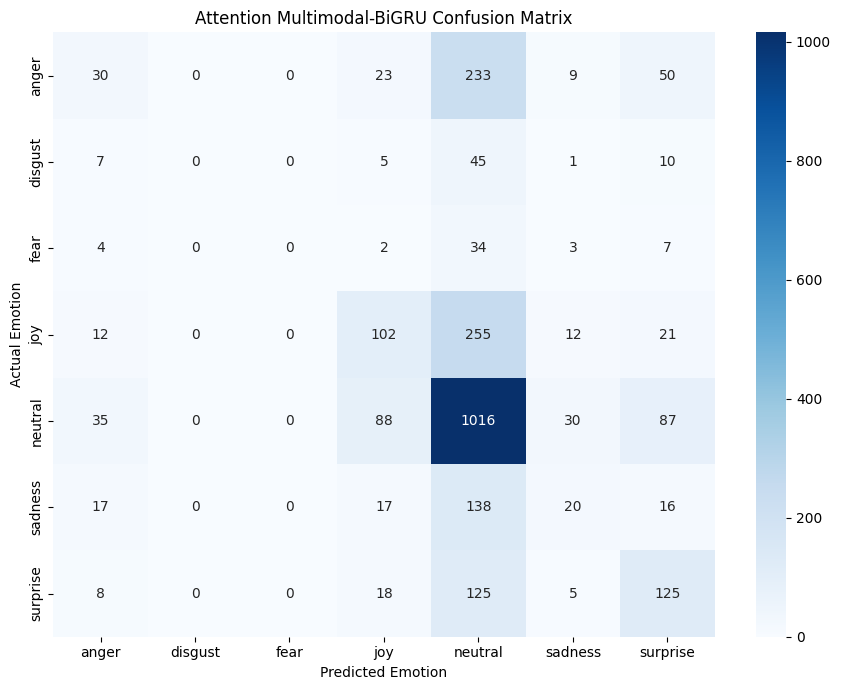

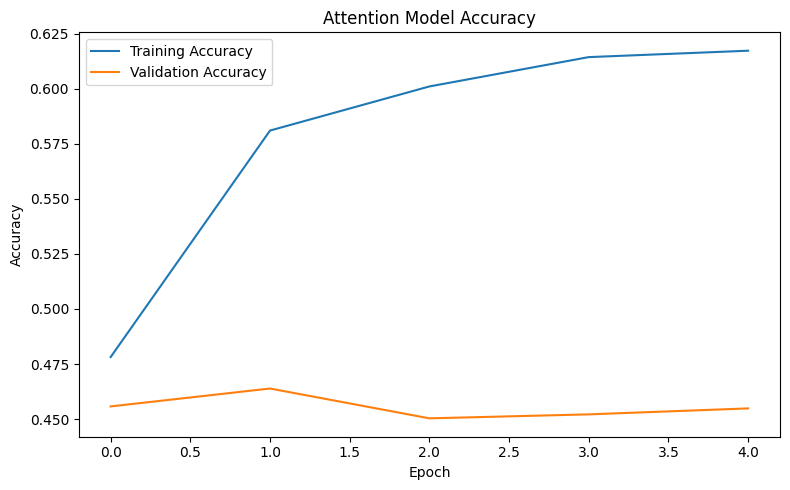

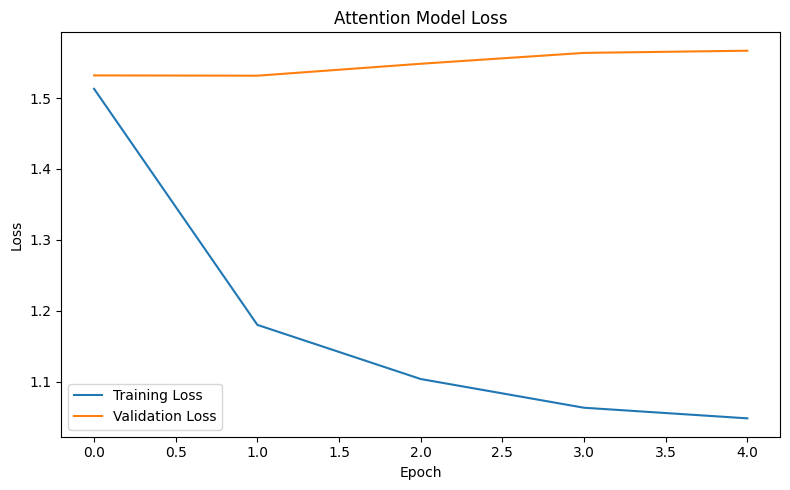

Attention experiment files saved successfully!
Saved location: /content/MELD/Improved_Experiments/Attention_Experiment
Files: ['Attention_Accuracy.png', 'Attention_Confusion_Matrix.png', 'Attention_Multimodal_BiGRU.keras', 'Attention_Loss.png', 'Attention_Classification_Report.csv']


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Create a separate folder
attention_dir = "/content/MELD/Improved_Experiments/Attention_Experiment"
os.makedirs(attention_dir, exist_ok=True)

# Save model
attention_model.save(
    os.path.join(attention_dir, "Attention_Multimodal_BiGRU.keras")
)

# Save classification report
report = classification_report(
    y_multimodal_test,
    y_attention_pred,
    labels=list(range(7)),
    target_names=EMOTIONS,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    os.path.join(attention_dir, "Attention_Classification_Report.csv")
)

# Save confusion matrix
cm = confusion_matrix(
    y_multimodal_test,
    y_attention_pred,
    labels=list(range(7))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=EMOTIONS,
    yticklabels=EMOTIONS
)
plt.title("Attention Multimodal-BiGRU Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()
plt.savefig(
    os.path.join(attention_dir, "Attention_Confusion_Matrix.png"),
    dpi=300
)
plt.show()
plt.close()

# Save training accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(attention_history.history["accuracy"], label="Training Accuracy")
plt.plot(attention_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Attention Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(attention_dir, "Attention_Accuracy.png"),
    dpi=300
)
plt.show()
plt.close()

# Save training loss graph
plt.figure(figsize=(8, 5))
plt.plot(attention_history.history["loss"], label="Training Loss")
plt.plot(attention_history.history["val_loss"], label="Validation Loss")
plt.title("Attention Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(attention_dir, "Attention_Loss.png"),
    dpi=300
)
plt.show()
plt.close()

print("Attention experiment files saved successfully!")
print("Saved location:", attention_dir)
print("Files:", os.listdir(attention_dir))

In [ ]:
import os
import pandas as pd
import numpy as np
import shutil
from sklearn.metrics import precision_score, recall_score, f1_score

results_dir = "/content/MELD/Improved_Experiments"
comparison_path = os.path.join(
    results_dir, "experiment_comparison.csv"
)

# Calculate exact attention metrics
attention_row = {
    "Model": "Attention Multimodal-BiGRU",
    "Accuracy": accuracy_score(
        y_multimodal_test, y_attention_pred
    ),
    "Macro Precision": precision_score(
        y_multimodal_test, y_attention_pred,
        average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_multimodal_test, y_attention_pred,
        average="macro", zero_division=0
    ),
    "Macro F1": f1_score(
        y_multimodal_test, y_attention_pred,
        average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_multimodal_test, y_attention_pred,
        average="weighted", zero_division=0
    )
}

# Update existing comparison
comparison = pd.read_csv(comparison_path)

# Avoid duplicate attention entries
comparison = comparison[
    comparison["Model"] != "Attention Multimodal-BiGRU"
]

comparison = pd.concat(
    [comparison, pd.DataFrame([attention_row])],
    ignore_index=True
)

comparison.to_csv(comparison_path, index=False)

print("UPDATED MODEL COMPARISON")
print("-" * 65)
print(comparison.round(4).to_string(index=False))

# Create final improved experiments ZIP
zip_path = "/content/MELD_Improved_Experiments_Final.zip"

if os.path.exists(zip_path):
    os.remove(zip_path)

shutil.make_archive(
    zip_path.replace(".zip", ""),
    "zip",
    results_dir
)

print("\nFINAL ZIP CREATED SUCCESSFULLY!")
print("Location:", zip_path)
print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")

UPDATED MODEL COMPARISON
-----------------------------------------------------------------
                          Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
                    Audio-BiGRU    0.1521           0.1670        0.1809    0.1270       0.1688
                     Text-BiGRU    0.2839           0.2667        0.3032    0.2435       0.3061
      Original Multimodal-BiGRU    0.2705           0.2512        0.2982    0.2227       0.2813
         Tuned Multimodal-BiGRU    0.5000           0.2737        0.2008    0.1663       0.3793
Class-Weighted Multimodal-BiGRU    0.2847           0.2350        0.2595    0.2154       0.3038
     Attention Multimodal-BiGRU    0.4954           0.2659        0.2415    0.2363       0.4365

FINAL ZIP CREATED SUCCESSFULLY!
Location: /content/MELD_Improved_Experiments_Final.zip
Size: 17.5 MB


In [ ]:
from google.colab import files

files.download("/content/MELD_Improved_Experiments_Final.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>